# Q1 — Population Structure

**Research question:** What is the functional organization of PPC during sensory-guided decision-making?

**Abstract claim:** *"Parietal activity is dominated by decision and kinematic variables organized into functionally distinct clusters occupying near-orthogonal subspaces."*

**Analyses:**
- **Sec 0** — Setup & data loading
- **Sec 1** — Baseline model performance (% responsive, FDE distributions, per-mouse summary)
- **Sec 2** — Example neuron traces (model validation)
- **Sec 3** — Population encoding structure (neuron types, lesion profiles, mixed selectivity, heatmap)
- **Sec 4** — PCA of the encoding space (scree, loadings, 2D/3D scatter)

**Data required:** `Model_1_results/glm_M1_full.pkl` and `glm_M1_lesion_all.pkl` for all sessions.

## Section 0 — Setup & Data Loading

In [1]:
import os, sys, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib import rcParams
from scipy import stats
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA

GLM_DIR = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model'
if GLM_DIR not in sys.path:
    sys.path.insert(0, GLM_DIR)
from core.session_pipeline import BASE_DATA_PATH, MODEL_1_DIR, Y_SCALE, Y_SMOOTH_SIGMA

os.makedirs(os.path.join(GLM_DIR, 'figures'), exist_ok=True)

# ── Plot style ─────────────────────────────────────────────────────────────
rcParams['font.family']       = 'Arial'
rcParams['axes.spines.right'] = False
rcParams['axes.spines.top']   = False
rcParams['axes.labelsize']    = 7
rcParams['xtick.labelsize']   = 7
rcParams['ytick.labelsize']   = 7
rcParams['figure.dpi']        = 800

# ── Constants ─────────────────────────────────────────────────────────────
CTX_COLORS_STR = {'cg': '#9B59B6', 'visual': '#EC008C', 'audio': '#27AAE1'}

M1_GROUPS = [
    'position_only',
    'audio_context', 'audio_stim',
    'visual_context', 'visual_stim',
    'velocity',
    'choice_spatial', 'turn_onset',
    'outcome',
]
GROUP_LABELS = {
    'position_only':  'Position',  'audio_context':  'Audio Ctx',
    'audio_stim':     'Audio Stim','visual_context': 'Visual Ctx',
    'visual_stim':    'Visual Stim','velocity':       'Velocity',
    'choice_spatial': 'Choice',    'turn_onset':     'Turn Onset',
    'outcome':        'Outcome',
}
GROUP_COLORS = {
    'position_only':  '#9B59B6', 'audio_context':  '#27AAE1',
    'audio_stim':     '#1A7AAF', 'visual_context': '#EC008C',
    'visual_stim':    '#A8005E', 'velocity':       '#2ECC71',
    'choice_spatial': '#E67E22', 'turn_onset':     '#E74C3C',
    'outcome':        '#F39C12',
}
CLASS_COLORS = {**GROUP_COLORS, 'mixed': '#95A5A6', 'unclassified': '#BDC3C7'}

MERGE_GROUPS = {
    'Kinematics': ['position_only', 'velocity'],
    'Audio':      ['audio_context', 'audio_stim'],
    'Visual':     ['visual_context', 'visual_stim'],
    'Choice':     ['choice_spatial', 'turn_onset'],
    'Outcome':    ['outcome'],
}
MERGE_ORDER  = ['Kinematics', 'Audio', 'Visual', 'Choice', 'Outcome']
MERGE_COLORS = {
    'Kinematics': '#9B59B6', 'Audio': '#27AAE1', 'Visual': '#EC008C',
    'Choice': '#E67E22',    'Outcome': '#F39C12',
}

RESP_THRESHOLD = 0.1
print('Setup complete')

Setup complete


In [2]:
# ── Session registry ──────────────────────────────────────────────────────
PPC_AVC = {
    'IS-2-1L': ['2025-03-10', '2025-03-11', '2025-03-12', '2025-03-13',
                '2025-03-20', '2025-03-26', '2025-04-02', '2025-04-04',
                '2025-04-08', '2025-04-09', '2025-05-05',
                '2025-05-28', '2025-05-30', '2025-11-20'],
    'IS-3-1R': ['2024-12-23', '2024-12-24'],
    'JP-2-1L': ['2025-08-19', '2025-08-26', '2025-09-16', '2025-09-17',
                '2025-09-19', '2025-09-22'],
    'KA-1-00': ['2025-12-16', '2026-01-08'],
    'KA-2-00': ['2026-01-08', '2026-01-13', '2026-01-14'],
    'KO-5-1L': ['2026-03-05', '2026-03-06', '2026-03-12', '2026-03-13', '2026-03-24'],
    'KO-6-00': ['2026-03-12', '2026-03-23', '2026-03-25'],
}
total = sum(len(v) for v in PPC_AVC.values())
print(f'Registry: {len(PPC_AVC)} mice | {total} sessions')

Registry: 7 mice | 35 sessions


In [3]:
def load_sessions(sessions_dict, model_dir, prefix):
    """Load full + lesion results for a given model."""
    sessions = []
    for mouse_ID, dates in sessions_dict.items():
        for date in dates:
            res_dir     = os.path.join(BASE_DATA_PATH, mouse_ID, date, model_dir)
            full_path   = os.path.join(res_dir, f'{prefix}_full.pkl')
            lesion_path = os.path.join(res_dir, f'{prefix}_lesion_all.pkl')
            if not os.path.exists(full_path):
                continue
            with open(full_path, 'rb') as f:
                full_res = pickle.load(f)
            lesion_res = None
            if os.path.exists(lesion_path):
                with open(lesion_path, 'rb') as f:
                    lesion_res = pickle.load(f)
            n = full_res['test_frac_dev'].shape[0]
            sessions.append(dict(mouse_ID=mouse_ID, date=date,
                                 full_res=full_res, lesion_res=lesion_res))
            tag = '+ lesion' if lesion_res else '  no lesion'
            print(f'  {mouse_ID}/{date}  n={n:5d}  {tag}')
    print(f'Loaded {len(sessions)} sessions')
    return sessions


def build_neuron_df(sessions, resp_threshold=0.1, mixed_margin=0.5):
    """Build per-neuron DataFrame with FDE, per-context FDE, and lesion deltas."""
    rows = []
    for s in sessions:
        mouse_ID, date = s['mouse_ID'], s['date']
        full_res, lesion_res = s['full_res'], s['lesion_res']
        n = len(full_res['test_frac_dev'])
        base = {
            'mouse_ID':        [mouse_ID]*n,
            'date':            [date]*n,
            'neuron_idx':      np.arange(n),
            'test_frac_dev':   full_res['test_frac_dev'],
            'cv_frac_dev':     full_res.get('cv_frac_dev', np.full(n, np.nan)),
            'test_r2':         full_res.get('test_trial_avg_r2', np.full(n, np.nan)),
            'frac_dev_cg':     full_res['test_frac_dev_per_ctx'].get(0, np.zeros(n)),
            'frac_dev_visual': full_res['test_frac_dev_per_ctx'].get(1, np.zeros(n)),
            'frac_dev_audio':  full_res['test_frac_dev_per_ctx'].get(2, np.zeros(n)),
        }
        df_s = pd.DataFrame(base)
        if lesion_res is not None:
            for grp in lesion_res['groups']:
                df_s[f'delta_fd_{grp}'] = lesion_res['delta_frac_dev'].get(grp, np.full(n, np.nan))
                df_s[f'delta_r2_{grp}'] = lesion_res['delta_r2'].get(grp, np.full(n, np.nan))
        rows.append(df_s)

    df = pd.concat(rows, ignore_index=True)
    df['neuron_uid'] = df['mouse_ID'] + '_' + df['date'] + '_n' + df['neuron_idx'].astype(str)
    df = df.set_index('neuron_uid')
    df['is_responsive'] = df['test_frac_dev'] > resp_threshold

    # Dominant group classification from lesion deltas
    delta_cols = [c for c in df.columns if c.startswith('delta_fd_')]
    if delta_cols:
        dc = df[delta_cols].clip(lower=0)
        df['dominant_group'] = dc.idxmax(axis=1).str.replace('delta_fd_', '', regex=False)
        df['dominant_delta'] = dc.max(axis=1)
        _dc = dc.to_numpy().copy()
        _dc[np.arange(len(_dc)), dc.values.argmax(axis=1)] = 0.0
        df['runner_up_group'] = (
            pd.Series(np.array(delta_cols)[_dc.argmax(axis=1)], index=df.index)
            .str.replace('delta_fd_', '', regex=False)
        )
        df['runner_up_delta'] = _dc.max(axis=1)
        with np.errstate(divide='ignore', invalid='ignore'):
            df['mixedness'] = np.where(
                df['dominant_delta'] > 0,
                df['runner_up_delta'] / df['dominant_delta'], 0.0
            )
        df['is_mixed'] = df['mixedness'] >= mixed_margin
        df['neuron_class'] = np.where(
            ~df['is_responsive'] | (df['dominant_delta'] <= 0), 'unclassified',
            np.where(df['is_mixed'], 'mixed', df['dominant_group'])
        )

    # Context preference
    df['cg_advantage'] = (
        df['frac_dev_cg'] - df[['frac_dev_visual', 'frac_dev_audio']].max(axis=1)
    )
    df['vis_aud_ci'] = (
        (df['frac_dev_visual'] - df['frac_dev_audio']) /
        (df['frac_dev_visual'] + df['frac_dev_audio'] + 1e-8)
    )

    n_resp = df['is_responsive'].sum()
    print(f'{len(df):,} neurons total | {n_resp:,} responsive ({n_resp/len(df)*100:.1f}%)')
    return df


print('Loaders defined')

Loaders defined


In [24]:
print('Loading Model 1...')
sessions_m1 = load_sessions(PPC_AVC, model_dir='Model_1_results', prefix='glm_M1')
df_m1   = build_neuron_df(sessions_m1)
resp_m1 = df_m1['is_responsive']

print('\nLoading Coupling model...')
sessions_coup = load_sessions(PPC_AVC, model_dir='coupling_results', prefix='glm_coupling')
df_coup   = build_neuron_df(sessions_coup)
resp_coup = df_coup['is_responsive']

print(f'\nModel 1  : {resp_m1.sum():,} responsive')
print(f'Coupling : {resp_coup.sum():,} responsive')

Loading Model 1...
  IS-2-1L/2025-03-10  n= 2115  + lesion
  IS-2-1L/2025-03-11  n= 1958  + lesion
  IS-2-1L/2025-03-12  n= 1783  + lesion
  IS-2-1L/2025-03-13  n= 1143    no lesion
  IS-2-1L/2025-03-20  n= 1800  + lesion
  IS-2-1L/2025-03-26  n= 1757  + lesion
  IS-2-1L/2025-04-02  n= 1884  + lesion
  IS-2-1L/2025-04-04  n= 2019  + lesion
  IS-2-1L/2025-04-08  n= 2049  + lesion
  IS-2-1L/2025-04-09  n= 1598  + lesion
  IS-2-1L/2025-05-05  n= 2147  + lesion
  IS-2-1L/2025-05-28  n= 1451  + lesion
  IS-2-1L/2025-05-30  n= 1122  + lesion
  IS-2-1L/2025-11-20  n= 1874  + lesion
  IS-3-1R/2024-12-23  n= 1855  + lesion
  IS-3-1R/2024-12-24  n= 2139  + lesion
  JP-2-1L/2025-08-19  n= 2325  + lesion
  JP-2-1L/2025-08-26  n= 1830  + lesion
  JP-2-1L/2025-09-16  n= 1654  + lesion
  JP-2-1L/2025-09-17  n= 1135  + lesion
  JP-2-1L/2025-09-19  n= 1566  + lesion
  JP-2-1L/2025-09-22  n= 1835  + lesion
  KA-1-00/2025-12-16  n= 1274  + lesion
  KA-1-00/2026-01-08  n= 1555  + lesion
  KA-2-00/2026-01-

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_80259/3351276688.py:60: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  df['dominant_group'] = dc.idxmax(axis=1).str.replace('delta_fd_', '', regex=False)


56,141 neurons total | 26,037 responsive (46.4%)

Loading Coupling model...
  IS-2-1L/2025-03-10  n= 2115  + lesion
  IS-2-1L/2025-03-11  n= 1958  + lesion
  IS-2-1L/2025-03-12  n= 1783  + lesion
  IS-2-1L/2025-03-13  n= 1143  + lesion
  IS-2-1L/2025-03-20  n= 1800  + lesion
  IS-2-1L/2025-03-26  n= 1757  + lesion
  IS-2-1L/2025-04-02  n= 1884  + lesion
  IS-2-1L/2025-04-04  n= 2019  + lesion
  IS-2-1L/2025-04-08  n= 2049  + lesion
  IS-2-1L/2025-04-09  n= 1598  + lesion
  IS-2-1L/2025-05-05  n= 2147  + lesion
  IS-2-1L/2025-05-28  n= 1451  + lesion
  IS-2-1L/2025-05-30  n= 1122  + lesion
  IS-2-1L/2025-11-20  n= 1874  + lesion
  IS-3-1R/2024-12-23  n= 1855  + lesion
  IS-3-1R/2024-12-24  n= 2139  + lesion
  JP-2-1L/2025-08-19  n= 2325  + lesion
  JP-2-1L/2025-08-26  n= 1830  + lesion
  JP-2-1L/2025-09-16  n= 1654  + lesion
  JP-2-1L/2025-09-17  n= 1135  + lesion
  JP-2-1L/2025-09-19  n= 1566  + lesion
  JP-2-1L/2025-09-22  n= 1835  + lesion
  KA-1-00/2025-12-16  n= 1274  + lesion
  KA

## Section 1 — Baseline Model Performance

How well does Model 1 capture neural activity across the population?

- **1a** Donut: % of neurons with FDE > threshold
- **1b** FDE histogram + CDF
- **1c** Summary bar: grand mean FDE ± SEM across sessions
- **1d** Per-mouse violin: FDE distribution per animal

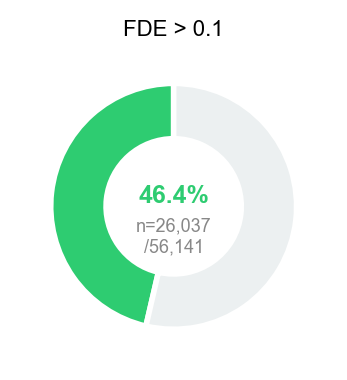

In [5]:
# ── 1a. Responsiveness donut ──────────────────────────────────────────────
def plot_responsiveness_donut(df, threshold=RESP_THRESHOLD, figsize=(2.0, 2.0)):
    n_total = len(df)
    n_resp  = (df['test_frac_dev'] > threshold).sum()
    pct     = n_resp / n_total * 100
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    ax.pie(
        [n_resp, n_total - n_resp],
        colors=['#2ECC71', '#ECF0F1'], startangle=90,
        wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    )
    ax.text(0,  0.08, f'{pct:.1f}%', ha='center', va='center',
            fontsize=9, color='#2ECC71', fontweight='bold')
    ax.text(0, -0.25, f'n={n_resp:,}\n/{n_total:,}', ha='center', va='center',
            fontsize=6.5, color='#888888')
    ax.set_title(f'FDE > {threshold}', fontsize=8)
    plt.tight_layout()
    return fig

fig = plot_responsiveness_donut(df_m1)
plt.savefig('figures/Q1_responsiveness_donut.svg', bbox_inches='tight', facecolor='white')
plt.show()

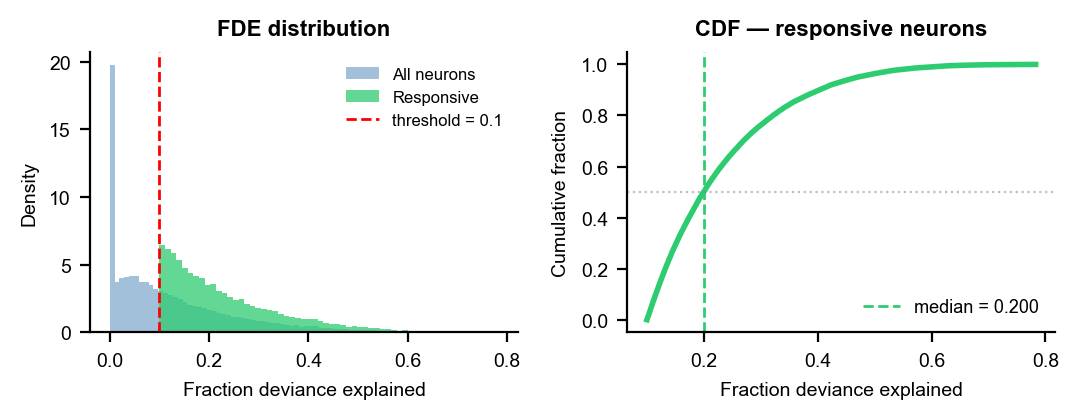

In [6]:
# ── 1b. FDE distribution — histogram + CDF ───────────────────────────────
fd_all  = df_m1['test_frac_dev'].values
fd_resp = df_m1.loc[resp_m1, 'test_frac_dev'].values

fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.2), dpi=200)

ax = axes[0]
ax.hist(fd_all,  bins=80, color='steelblue', alpha=0.5, density=True, label='All neurons')
ax.hist(fd_resp, bins=60, color='#2ECC71',   alpha=0.75, density=True, label='Responsive')
ax.axvline(RESP_THRESHOLD, color='red', ls='--', lw=1.0,
           label=f'threshold = {RESP_THRESHOLD}')
ax.set_xlabel('Fraction deviance explained', fontsize=7)
ax.set_ylabel('Density', fontsize=7)
ax.set_title('FDE distribution', fontsize=8, fontweight='bold')
ax.legend(fontsize=6, frameon=False)
sns.despine(ax=ax)

ax = axes[1]
x = np.sort(fd_resp)
y = np.linspace(0, 1, len(x))
ax.plot(x, y, color='#2ECC71', lw=2)
med = np.median(fd_resp)
ax.axvline(med, color='#2ECC71', ls='--', lw=1.0, label=f'median = {med:.3f}')
ax.axhline(0.5, color='gray', ls=':', lw=0.8, alpha=0.5)
ax.set_xlabel('Fraction deviance explained', fontsize=7)
ax.set_ylabel('Cumulative fraction', fontsize=7)
ax.set_title('CDF — responsive neurons', fontsize=8, fontweight='bold')
ax.legend(fontsize=6.5, frameon=False)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig('figures/Q1_fde_distribution.svg', bbox_inches='tight', facecolor='white')
plt.show()

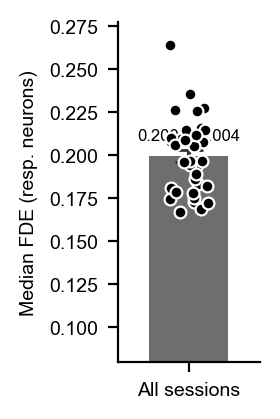

In [7]:
# ── 1c. Grand mean FDE bar ± SEM across sessions ─────────────────────────
def plot_frac_dev_summary(df, resp_threshold=RESP_THRESHOLD, figsize=(1.5, 2.2)):
    resp_df = df[df['test_frac_dev'] > resp_threshold]
    sess_medians = (
        resp_df.groupby(['mouse_ID', 'date'])['test_frac_dev']
        .median().reset_index().rename(columns={'test_frac_dev': 'median_fd'})
    )
    grand_mean = sess_medians['median_fd'].mean()
    grand_sem  = sess_medians['median_fd'].sem()

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    ax.bar(0, grand_mean, yerr=grand_sem, width=0.5, color='#555555', alpha=0.85,
           error_kw=dict(elinewidth=1.5, capsize=5, ecolor='#333333'), zorder=2)
    rng = np.random.default_rng(seed=0)
    jitter = rng.uniform(-0.12, 0.12, size=len(sess_medians))
    for i, (_, row) in enumerate(sess_medians.iterrows()):
        ax.scatter(jitter[i], row['median_fd'], color='black', s=18,
                   zorder=4, edgecolors='white', linewidths=0.8)
    ax.text(0, grand_mean + grand_sem + 0.004,
            f'{grand_mean:.3f}+/-{grand_sem:.3f}',
            ha='center', va='bottom', fontsize=6)
    ax.set_xticks([0])
    ax.set_xticklabels(['All sessions'], fontsize=7)
    ax.set_xlim(-0.45, 0.45)
    ax.set_ylim(bottom=resp_threshold * 0.8)
    ax.set_ylabel('Median FDE (resp. neurons)', fontsize=7)
    sns.despine()
    plt.tight_layout()
    return fig

fig = plot_frac_dev_summary(df_m1)
plt.savefig('figures/Q1_fde_summary_bar.svg', bbox_inches='tight', facecolor='white')
plt.show()

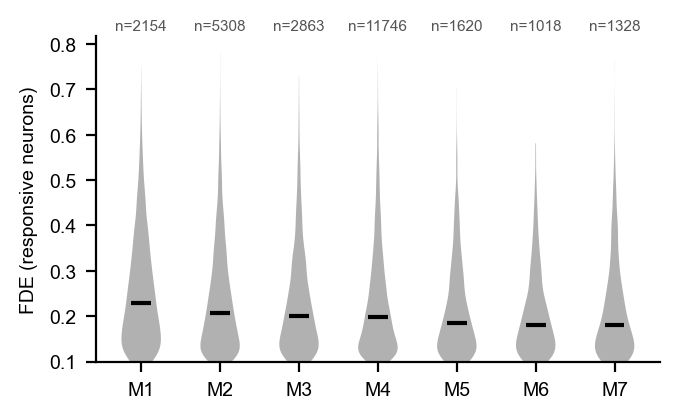

In [8]:
# ── 1d. FDE per mouse — violin ────────────────────────────────────────────
def plot_fde_per_mouse(df, resp_threshold=RESP_THRESHOLD, figsize=(3.5, 2.2)):
    resp_df = df[df['test_frac_dev'] > resp_threshold]
    mouse_stats = (
        resp_df.groupby('mouse_ID')['test_frac_dev']
        .agg(median='median', n_neurons='count').reset_index()
        .sort_values('median', ascending=False).reset_index(drop=True)
    )
    mouse_stats['label'] = [f'M{i+1}' for i in range(len(mouse_stats))]
    neuron_data = [
        resp_df[resp_df['mouse_ID'] == m]['test_frac_dev'].values
        for m in mouse_stats['mouse_ID']
    ]
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    parts = ax.violinplot(neuron_data, positions=range(len(mouse_stats)),
                          showmedians=True, showextrema=False)
    for pc in parts['bodies']:
        pc.set_facecolor('#888888'); pc.set_alpha(0.65)
    parts['cmedians'].set_color('black'); parts['cmedians'].set_linewidth(1.5)
    for i, row in mouse_stats.iterrows():
        ax.text(i, 1.01, f'n={int(row["n_neurons"])}',
                ha='center', va='bottom', fontsize=5.5, color='#555555',
                transform=ax.get_xaxis_transform())
    ax.set_xticks(range(len(mouse_stats)))
    ax.set_xticklabels(mouse_stats['label'].tolist(), fontsize=7)
    ax.set_ylabel('FDE (responsive neurons)', fontsize=7)
    ax.set_ylim(bottom=resp_threshold)
    sns.despine()
    plt.tight_layout()
    return fig

fig = plot_fde_per_mouse(df_m1)
plt.savefig('figures/Q1_fde_per_mouse.svg', bbox_inches='tight', facecolor='white')
plt.show()

## Section 2 — Example Neuron Traces

Visual validation: do the model predictions match real neural dynamics?

We pick three neurons spanning the FDE range (high / medium / low), then find the 1000-frame window with the highest observed–predicted Pearson correlation for each.

In [9]:
from core.glm_class import make_prediction
from core.session_pipeline import add_coupling_predictor
from scipy.stats import pearsonr

FS       = 15.0
N_FRAMES = 1000

# ── Pick the session with the most responsive neurons ─────────────────────
session_counts = (
    df_m1[resp_m1].groupby(['mouse_ID', 'date']).size().sort_values(ascending=False)
)
ex_mouse, ex_date = session_counts.index[0]
print(f'Example session: {ex_mouse} / {ex_date}')

ex_session = next(
    s for s in sessions_m1
    if s['mouse_ID'] == ex_mouse and s['date'] == ex_date
)
full_res = ex_session['full_res']

# ── Load design matrix and neural activity ────────────────────────────────
stacked_path = os.path.join(BASE_DATA_PATH, ex_mouse, ex_date, 'glm_data_stacked.pkl')
with open(stacked_path, 'rb') as f:
    glm_data = pickle.load(f)

X = glm_data['X']
Y = glm_data['Y'] * Y_SCALE
if Y_SMOOTH_SIGMA > 0:
    Y = gaussian_filter1d(Y, sigma=Y_SMOOTH_SIGMA, axis=0)
    Y = np.clip(Y, 0.0, None)

W  = full_res['weights']
w0 = full_res['w0'].flatten()

# If the model was fit with coupling predictors, re-add them to X
if W.shape[0] > X.shape[1]:
    X, _, _ = add_coupling_predictor(
        X, Y, glm_data['predictor_info'], n_pcs=5, n_lag_bases=4, lag_frames=8
    )
    print(f'Coupling predictors added: X shape -> {X.shape}')

Y_pred_full = make_prediction(X, W, w0, activation='exp')
print(f'Y shape: {Y.shape} | Y_pred shape: {Y_pred_full.shape}')

Example session: JP-2-1L / 2025-08-19
Y shape: (49195, 2325) | Y_pred shape: (49195, 2325)


In [10]:
# ── Best-window search + neuron selection ────────────────────────────────
def find_best_window(y_obs, y_pred, n_frames=N_FRAMES, stride=50, min_mean=0.1):
    """Slide a window of n_frames; return start with highest Pearson r."""
    T = len(y_obs)
    best_r, best_start = -np.inf, 0
    for start in range(0, T - n_frames, stride):
        yo = y_obs[start:start + n_frames]
        yp = y_pred[start:start + n_frames]
        if yo.mean() < min_mean or yo.std() < 1e-6 or yp.std() < 1e-6:
            continue
        r, _ = pearsonr(yo, yp)
        if r > best_r:
            best_r, best_start = r, start
    return best_start, best_r


sess_df = df_m1[
    (df_m1['mouse_ID'] == ex_mouse) & (df_m1['date'] == ex_date)
]
fd_resp_sess = sess_df.loc[sess_df['is_responsive'], 'test_frac_dev']

def pick_neuron(lo, hi):
    subset = sess_df[
        (sess_df['test_frac_dev'] >= lo) & (sess_df['test_frac_dev'] < hi)
    ]
    if subset.empty:
        raise ValueError(f'No neuron found with FDE in [{lo:.2f}, {hi:.2f})')
    mid = (lo + hi) / 2
    return subset.iloc[
        (subset['test_frac_dev'] - mid).abs().argsort().values[0]
    ]

p90 = np.percentile(fd_resp_sess, 90)
target_neurons = [
    pick_neuron(p90, fd_resp_sess.max() + 0.01),   # high FDE
    pick_neuron(0.40, 0.65),                         # medium FDE
    pick_neuron(RESP_THRESHOLD, 0.25),               # low (but responsive)
]
print('Selected neurons:')
for row in target_neurons:
    print(f'  idx={int(row["neuron_idx"]):<5d}  FDE={row["test_frac_dev"]:.3f}')

Selected neurons:
  idx=1041   FDE=0.609
  idx=576    FDE=0.525
  idx=915    FDE=0.175


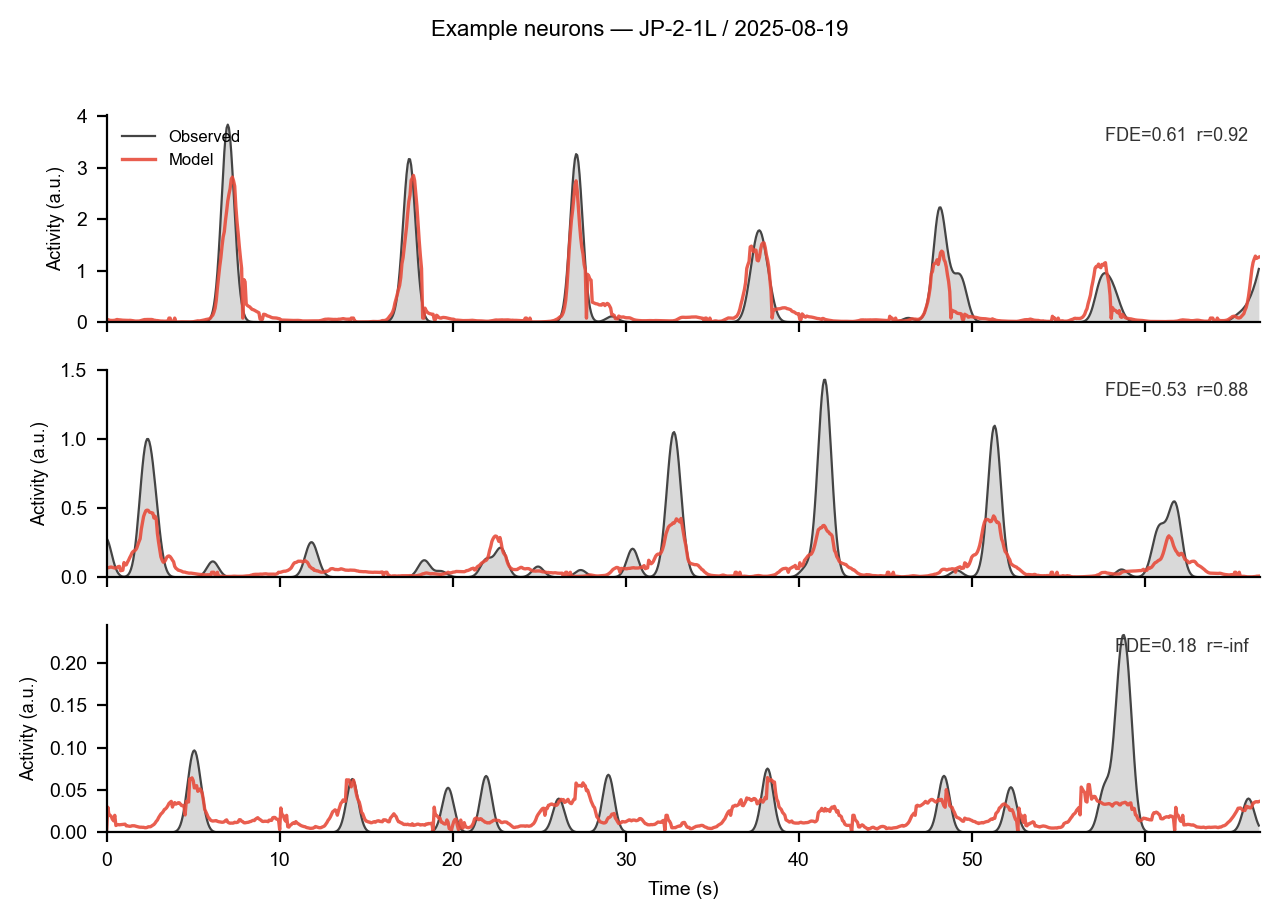

In [11]:
# ── Plot example traces ───────────────────────────────────────────────────
t_axis = np.arange(N_FRAMES) / FS

fig, axes = plt.subplots(
    len(target_neurons), 1,
    figsize=(6.5, 1.5 * len(target_neurons)), dpi=200, sharex=True
)

for ax, row in zip(axes, target_neurons):
    nidx  = int(row['neuron_idx'])
    fde   = float(row['test_frac_dev'])
    t0, r = find_best_window(Y[:, nidx], Y_pred_full[:, nidx])

    y_obs  = Y[t0:t0 + N_FRAMES, nidx]
    y_pred = Y_pred_full[t0:t0 + N_FRAMES, nidx]

    ax.fill_between(t_axis, y_obs, alpha=0.2, color='#444444', lw=0)
    ax.plot(t_axis, y_obs,  color='#444444', lw=0.8, label='Observed')
    ax.plot(t_axis, y_pred, color='#E74C3C', lw=1.2, alpha=0.9, label='Model')
    ax.set_ylabel('Activity (a.u.)', fontsize=6.5)
    ax.set_xlim(0, N_FRAMES / FS)
    ax.set_ylim(bottom=0)
    ax.text(0.99, 0.94, f'FDE={fde:.2f}  r={r:.2f}',
            transform=ax.transAxes, ha='right', va='top',
            fontsize=6.5, color='#333333')
    if ax is axes[0]:
        ax.legend(fontsize=6, frameon=False, loc='upper left')
    sns.despine(ax=ax)

axes[-1].set_xlabel('Time (s)', fontsize=7)
plt.suptitle(
    f'Example neurons — {ex_mouse} / {ex_date}', fontsize=8, y=1.01
)
plt.tight_layout()
plt.savefig('figures/Q1_example_traces.svg', bbox_inches='tight', facecolor='white')
plt.show()

## Section 3 — Population Encoding Structure

Using lesion analysis (unique contribution = full model FDE − lesion FDE) to characterize the dominant predictor group for each neuron.

> **Note:** Cells in this section require `glm_M1_lesion_all.pkl` to exist for each session (run `run_sessions.py` first). Sessions missing lesion results will be automatically excluded.

In [12]:
# ── 3a. Check lesion data availability ───────────────────────────────────
n_with_lesion    = sum(1 for s in sessions_m1 if s['lesion_res'] is not None)
n_without_lesion = len(sessions_m1) - n_with_lesion
print(f'Sessions with lesion results : {n_with_lesion}')
print(f'Sessions without             : {n_without_lesion}')

delta_cols = [f'delta_fd_{g}' for g in M1_GROUPS
              if f'delta_fd_{g}' in df_m1.columns]
if not delta_cols:
    print('\nNo lesion columns found in df_m1.')
    print('Run run_sessions.py to generate lesion results, then reload data.')
else:
    groups_present = [c.replace('delta_fd_', '') for c in delta_cols]
    print(f'\nLesion groups available: {groups_present}')
    df_resp = df_m1[resp_m1].copy()
    print(f'Responsive neurons with lesion data: '
          f"{df_resp[delta_cols[0]].notna().sum():,}")

Sessions with lesion results : 34
Sessions without             : 1

Lesion groups available: ['position_only', 'audio_context', 'audio_stim', 'visual_context', 'visual_stim', 'velocity', 'choice_spatial', 'turn_onset', 'outcome']
Responsive neurons with lesion data: 25,253


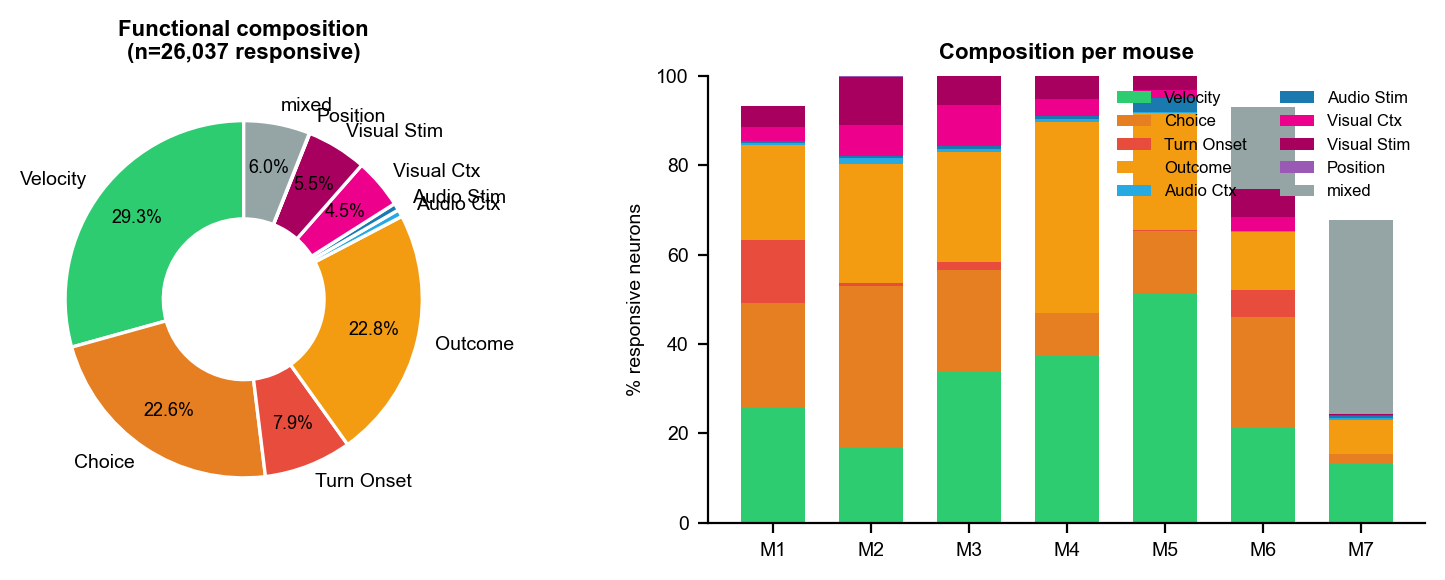

In [13]:
# ── 3b. Neuron type composition ───────────────────────────────────────────
if 'neuron_class' not in df_m1.columns:
    print('Skipping — no neuron_class column (lesion data required).')
else:
    df_resp = df_m1[resp_m1].copy()
    class_order = [
        'velocity', 'choice_spatial', 'turn_onset', 'outcome',
        'audio_context', 'audio_stim', 'visual_context', 'visual_stim',
        'position_only', 'mixed', 'unclassified'
    ]
    counts  = df_resp['neuron_class'].value_counts()
    present = [c for c in class_order if c in counts.index]
    vals    = [counts.get(c, 0) for c in present]
    colors  = [CLASS_COLORS.get(c, '#BDC3C7') for c in present]

    fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.0), dpi=200)

    # Donut
    ax = axes[0]
    _, _, autotexts = ax.pie(
        vals,
        labels=[GROUP_LABELS.get(c, c) for c in present],
        colors=colors,
        autopct=lambda p: f'{p:.1f}%' if p > 3 else '',
        startangle=90, pctdistance=0.75,
        wedgeprops=dict(width=0.55, edgecolor='white', linewidth=1.2),
        textprops={'fontsize': 7},
    )
    for at in autotexts: at.set_fontsize(6.5)
    ax.set_title(f'Functional composition\n(n={len(df_resp):,} responsive)',
                 fontsize=8, fontweight='bold')

    # Per-mouse stacked bar
    ax = axes[1]
    mice = sorted(df_resp['mouse_ID'].unique())
    mlabels = [f'M{i+1}' for i in range(len(mice))]
    bottom  = np.zeros(len(mice))
    for cls in present:
        fracs = [
            (df_resp[df_resp['mouse_ID'] == m]['neuron_class'] == cls).mean() * 100
            for m in mice
        ]
        ax.bar(mlabels, fracs, bottom=bottom,
               color=CLASS_COLORS.get(cls, '#BDC3C7'),
               label=GROUP_LABELS.get(cls, cls), width=0.65)
        bottom += np.array(fracs)
    ax.set_ylabel('% responsive neurons', fontsize=7)
    ax.set_title('Composition per mouse', fontsize=8, fontweight='bold')
    ax.legend(loc='upper right', fontsize=6, ncol=2, frameon=False)
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.savefig('figures/Q1_neuron_composition.svg', bbox_inches='tight', facecolor='white')
    plt.show()

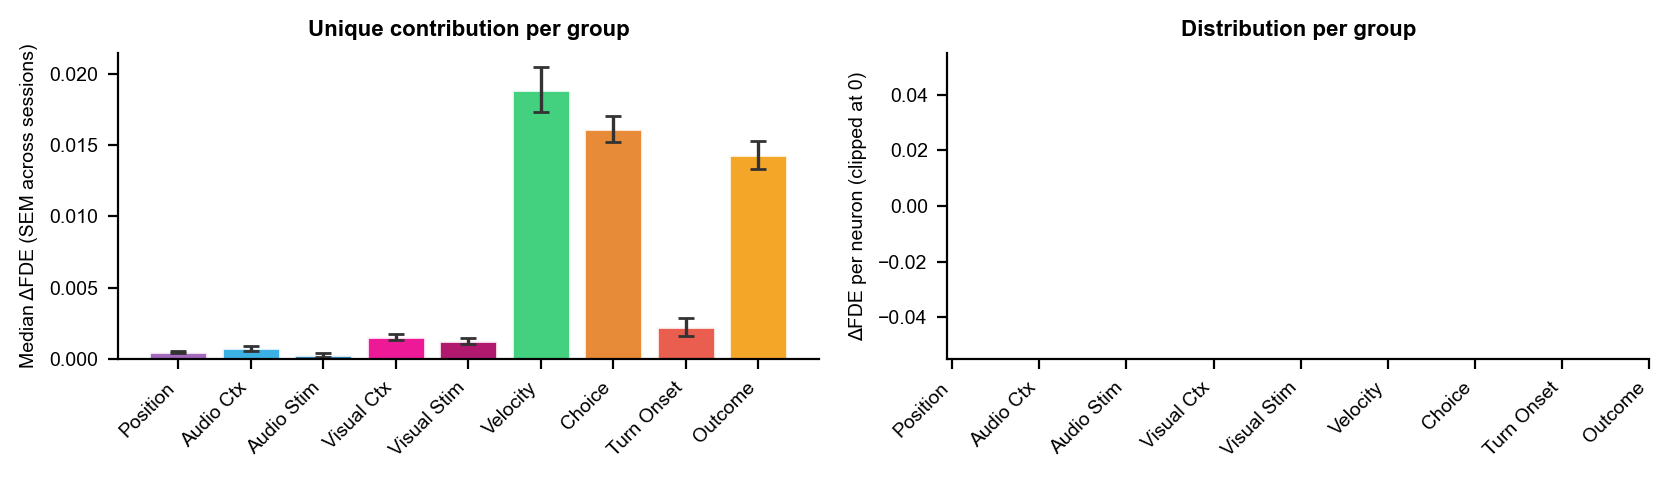

In [14]:
# ── 3c. Lesion contribution profiles ─────────────────────────────────────
if not delta_cols:
    print('Skipping — lesion data required.')
else:
    df_resp = df_m1[resp_m1].copy()
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.5), dpi=200)

    # Bar: median ± SEM (SEM across session medians)
    ax = axes[0]
    sess_grp = df_resp.groupby(['mouse_ID', 'date'])[delta_cols].median()
    medians  = [df_resp[c].median() for c in delta_cols]
    sems     = [sess_grp[c].sem()    for c in delta_cols]
    cols     = [GROUP_COLORS.get(c.replace('delta_fd_', ''), 'gray')
                for c in delta_cols]
    ax.bar(range(len(delta_cols)), medians, color=cols, edgecolor='white', alpha=0.9)
    ax.errorbar(range(len(delta_cols)), medians, yerr=sems,
                fmt='none', color='#333333', capsize=3, lw=1.2)
    ax.set_xticks(range(len(delta_cols)))
    ax.set_xticklabels(
        [GROUP_LABELS.get(c.replace('delta_fd_', ''), c) for c in delta_cols],
        rotation=45, ha='right', fontsize=7
    )
    ax.set_ylabel('Median ΔFDE (SEM across sessions)', fontsize=7)
    ax.set_title('Unique contribution per group', fontsize=8, fontweight='bold')
    ax.axhline(0, color='k', lw=0.7, ls='--', alpha=0.4)
    sns.despine(ax=ax)

    # Violin: per-neuron distribution
    ax = axes[1]
    data_v = [df_resp[c].clip(lower=0).values for c in delta_cols]
    vp = ax.violinplot(data_v, positions=range(len(delta_cols)),
                       showmedians=True, showextrema=False)
    for pc, c in zip(vp['bodies'], delta_cols):
        pc.set_facecolor(GROUP_COLORS.get(c.replace('delta_fd_', ''), 'gray'))
        pc.set_alpha(0.65)
    vp['cmedians'].set_color('black'); vp['cmedians'].set_linewidth(1.5)
    ax.set_xticks(range(len(delta_cols)))
    ax.set_xticklabels(
        [GROUP_LABELS.get(c.replace('delta_fd_', ''), c) for c in delta_cols],
        rotation=45, ha='right', fontsize=7
    )
    ax.set_ylabel('ΔFDE per neuron (clipped at 0)', fontsize=7)
    ax.set_title('Distribution per group', fontsize=8, fontweight='bold')
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.savefig('figures/Q1_lesion_profiles.svg', bbox_inches='tight', facecolor='white')
    plt.show()

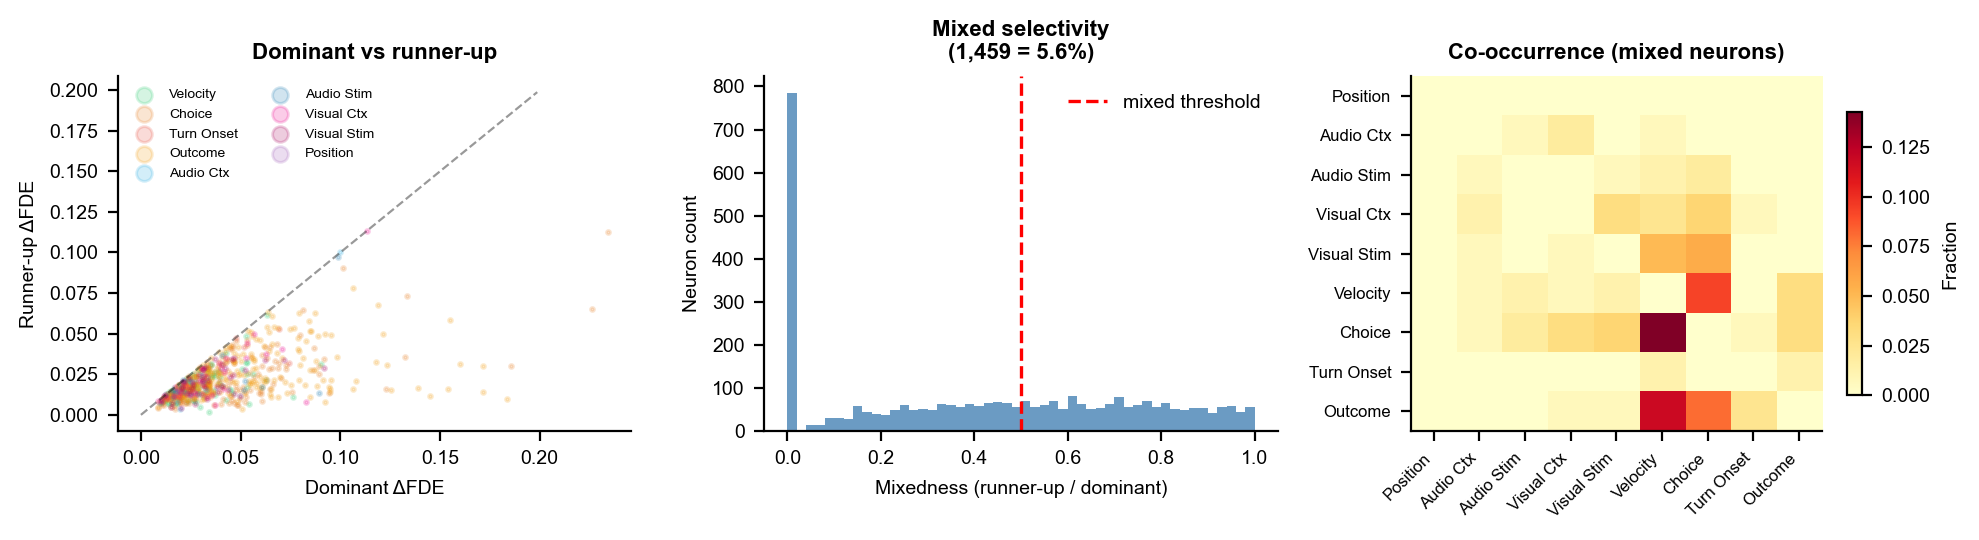

In [15]:
# ── 3d. Mixed selectivity analysis ───────────────────────────────────────
if 'mixedness' not in df_m1.columns:
    print('Skipping — lesion data required.')
else:
    df_resp = df_m1[resp_m1].copy()
    class_order = [
        'velocity', 'choice_spatial', 'turn_onset', 'outcome',
        'audio_context', 'audio_stim', 'visual_context', 'visual_stim',
        'position_only', 'mixed', 'unclassified'
    ]
    fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), dpi=200)

    # Scatter: dominant vs runner-up
    ax = axes[0]
    for cls in class_order:
        if cls in ('mixed', 'unclassified'): continue
        sub = df_resp[df_resp['dominant_group'] == cls]
        if len(sub) == 0: continue
        ax.scatter(sub['dominant_delta'], sub['runner_up_delta'],
                   s=2, alpha=0.2, color=CLASS_COLORS.get(cls, 'gray'),
                   label=GROUP_LABELS.get(cls, cls))
    lim = max(df_resp['dominant_delta'].quantile(0.99),
              df_resp['runner_up_delta'].quantile(0.99))
    ax.plot([0, lim], [0, lim], 'k--', lw=0.8, alpha=0.4)
    ax.set_xlabel('Dominant ΔFDE', fontsize=7)
    ax.set_ylabel('Runner-up ΔFDE', fontsize=7)
    ax.set_title('Dominant vs runner-up', fontsize=8, fontweight='bold')
    ax.legend(fontsize=5, markerscale=4, frameon=False, ncol=2)
    sns.despine(ax=ax)

    # Mixedness histogram
    ax = axes[1]
    ax.hist(df_resp['mixedness'], bins=50, color='steelblue',
            edgecolor='none', alpha=0.8)
    ax.axvline(0.5, color='red', ls='--', lw=1.2, label='mixed threshold')
    n_mixed = df_resp['is_mixed'].sum()
    ax.set_xlabel('Mixedness (runner-up / dominant)', fontsize=7)
    ax.set_ylabel('Neuron count', fontsize=7)
    ax.set_title(
        f'Mixed selectivity\n({n_mixed:,} = {n_mixed/len(df_resp)*100:.1f}%)',
        fontsize=8, fontweight='bold'
    )
    ax.legend(fontsize=7, frameon=False)
    sns.despine(ax=ax)

    # Co-occurrence heatmap for mixed neurons
    ax = axes[2]
    g_list = [g for g in M1_GROUPS
              if f'delta_fd_{g}' in df_m1.columns]
    mixed_df = df_resp[df_resp['is_mixed']]
    comat = np.zeros((len(g_list), len(g_list)))
    for i, gi in enumerate(g_list):
        for j, gj in enumerate(g_list):
            comat[i, j] = (
                (mixed_df['dominant_group'] == gi) &
                (mixed_df['runner_up_group'] == gj)
            ).sum()
    comat_norm = comat / (comat.sum() + 1e-9)
    im = ax.imshow(comat_norm, cmap='YlOrRd', aspect='auto')
    lbs = [GROUP_LABELS.get(g, g) for g in g_list]
    ax.set_xticks(range(len(g_list))); ax.set_xticklabels(lbs, rotation=45, ha='right', fontsize=6)
    ax.set_yticks(range(len(g_list))); ax.set_yticklabels(lbs, fontsize=6)
    ax.set_title('Co-occurrence (mixed neurons)', fontsize=8, fontweight='bold')
    plt.colorbar(im, ax=ax, label='Fraction', shrink=0.8)

    plt.tight_layout()
    plt.savefig('figures/Q1_mixed_selectivity.svg', bbox_inches='tight', facecolor='white')
    plt.show()

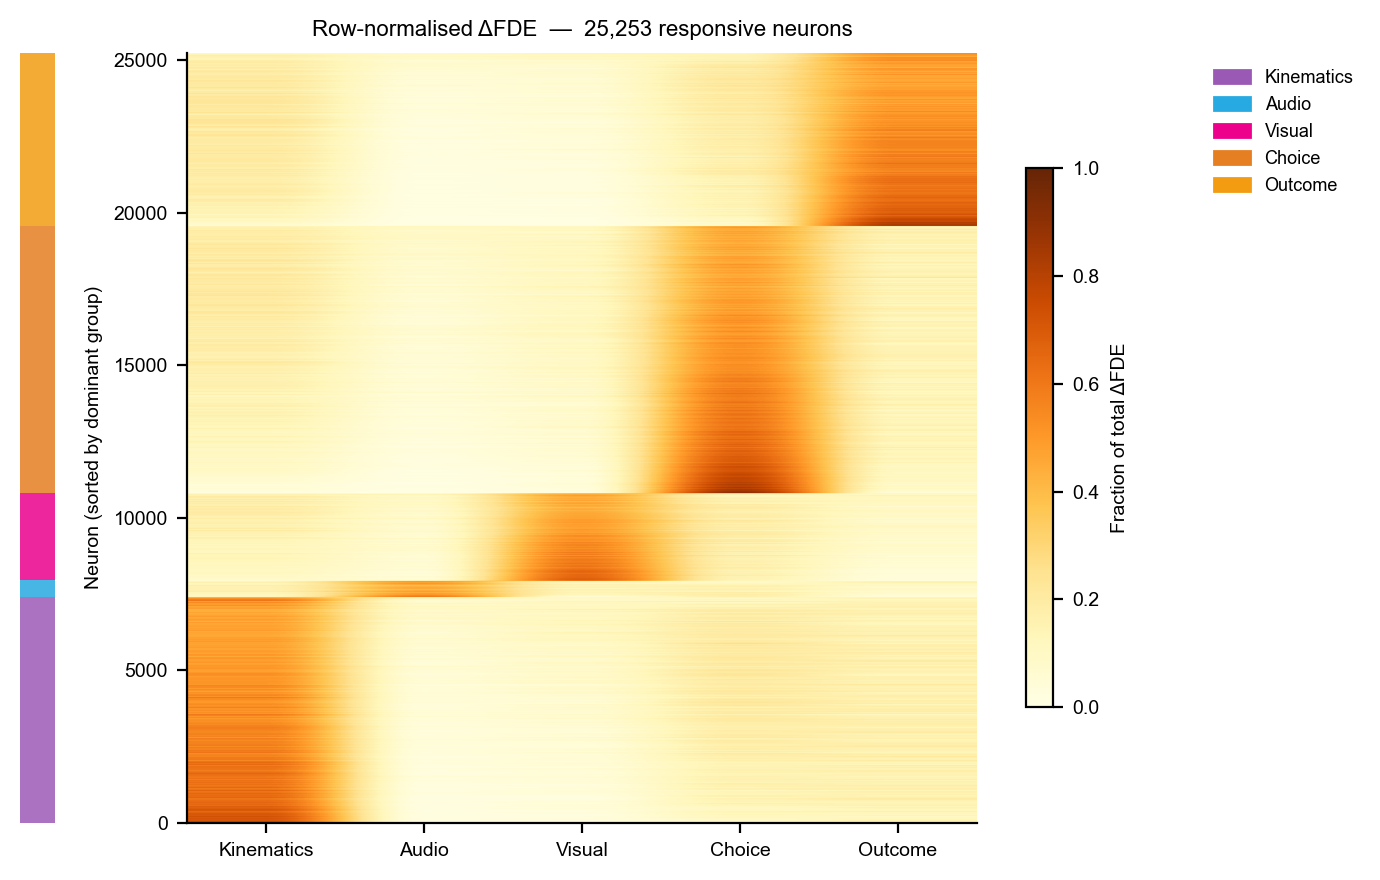

In [16]:
# ── 3e. Delta FDE heatmap (merged groups, row-normalised) ─────────────────
if not delta_cols:
    print('Skipping — lesion data required.')
else:
    df_delta_resp = (
        df_m1.loc[resp_m1, delta_cols]
        .clip(lower=0)
        .rename(columns=lambda c: c.replace('delta_fd_', ''))
        .dropna()
    )

    # Merge 9 groups -> 5 merged groups
    df_merged = pd.DataFrame(index=df_delta_resp.index)
    for name, src_cols in MERGE_GROUPS.items():
        present_src = [c for c in src_cols if c in df_delta_resp.columns]
        df_merged[name] = df_delta_resp[present_src].sum(axis=1)
    df_merged = df_merged[MERGE_ORDER]

    mat = df_merged.to_numpy()
    row_sum = mat.sum(axis=1, keepdims=True)
    row_sum[row_sum == 0] = 1
    mat_norm = mat / row_sum

    # Sort by dominant merged group, then by dominant delta (desc)
    dominant_merged = df_merged.idxmax(axis=1)
    group_rank = {g: i for i, g in enumerate(MERGE_ORDER)}
    sort_key   = dominant_merged.map(group_rank).values * 1e6 - mat.max(axis=1)
    order      = np.argsort(sort_key)
    mat_plot   = mat_norm[order]

    # Side color bar
    top_groups = dominant_merged.iloc[order].values

    fig, axes = plt.subplots(
        1, 2, figsize=(7, 4.5), dpi=200,
        gridspec_kw={'width_ratios': [0.035, 1]}
    )

    ax_bar = axes[0]
    for i, grp in enumerate(top_groups):
        color = MERGE_COLORS.get(grp, '#CCCCCC')
        r, g_c, b = int(color[1:3], 16)/255, int(color[3:5], 16)/255, int(color[5:7], 16)/255
        ax_bar.axhspan(i, i + 1, facecolor=(r, g_c, b), alpha=0.85)
    ax_bar.set_xlim(0, 1)
    ax_bar.set_ylim(0, len(top_groups))
    ax_bar.axis('off')

    ax = axes[1]
    im = ax.imshow(mat_plot, cmap='YlOrBr', aspect='auto',
                   origin='lower', vmin=0, vmax=1)
    ax.set_xticks(range(len(MERGE_ORDER)))
    ax.set_xticklabels(MERGE_ORDER, fontsize=7)
    ax.set_ylabel('Neuron (sorted by dominant group)', fontsize=7)
    ax.set_title(
        f'Row-normalised ΔFDE  —  {mat_plot.shape[0]:,} responsive neurons',
        fontsize=8
    )
    plt.colorbar(im, ax=ax, label='Fraction of total ΔFDE', shrink=0.7)

    handles = [mpatches.Patch(color=MERGE_COLORS[g], label=g) for g in MERGE_ORDER]
    ax.legend(handles=handles, fontsize=6.5, frameon=False,
              bbox_to_anchor=(1.28, 1.0), loc='upper left')

    plt.tight_layout()
    plt.savefig('figures/Q1_delta_fde_heatmap.svg', bbox_inches='tight', facecolor='white')
    plt.show()

## Section 4 — PCA of the Encoding Space

PCA on row-normalised ΔFDE vectors (merged groups) reveals the low-dimensional geometry of the encoding space. Near-orthogonal clusters support the abstract claim that different variables are encoded by largely separate populations.

- **4a** Build merged matrix and fit PCA
- **4b** Scree plot + PC loadings
- **4c** 2D scatter plots with 1-SD and 2-SD confidence ellipses
- **4d** 3D scatter with 1-SD ellipsoids

In [17]:
# ── 4a. Build merged X_norm and fit PCA ──────────────────────────────────
if not delta_cols:
    print('Skipping — lesion data required.')
    pca = None
else:
    delta_cols_pca = [f'delta_fd_{g}' for g in M1_GROUPS
                      if f'delta_fd_{g}' in df_m1.columns]
    df_delta_resp = (
        df_m1.loc[resp_m1, delta_cols_pca]
        .clip(lower=0)
        .rename(columns=lambda c: c.replace('delta_fd_', ''))
        .dropna()
    )

    df_merged_pca = pd.DataFrame(index=df_delta_resp.index)
    for name, src_cols in MERGE_GROUPS.items():
        present_src = [c for c in src_cols if c in df_delta_resp.columns]
        df_merged_pca[name] = df_delta_resp[present_src].sum(axis=1)
    df_merged_pca = df_merged_pca[MERGE_ORDER]

    X_delta   = df_merged_pca.to_numpy()
    X_clipped = np.clip(X_delta, 0, None)
    row_sum   = X_clipped.sum(axis=1, keepdims=True)
    row_sum[row_sum == 0] = 1
    X_norm = X_clipped / row_sum

    pca    = PCA()
    pca.fit(X_norm)
    scores = pca.transform(X_norm)

    cumvar = np.cumsum(pca.explained_variance_ratio_)
    n_pcs_90 = int(np.searchsorted(cumvar, 0.90)) + 1
    n_pcs_95 = int(np.searchsorted(cumvar, 0.95)) + 1

    print(f'Neurons : {X_norm.shape[0]:,}  |  Groups : {X_norm.shape[1]}')
    for i, v in enumerate(pca.explained_variance_ratio_):
        print(f'  PC{i+1}: {v*100:.1f}%  (cumulative: {cumvar[i]*100:.1f}%)')
    print(f'PCs for 90% variance: {n_pcs_90}  |  95%: {n_pcs_95}')

Neurons : 25,253  |  Groups : 5
  PC1: 40.4%  (cumulative: 40.4%)
  PC2: 31.4%  (cumulative: 71.7%)
  PC3: 23.0%  (cumulative: 94.7%)
  PC4: 5.3%  (cumulative: 100.0%)
  PC5: 0.0%  (cumulative: 100.0%)
PCs for 90% variance: 3  |  95%: 4


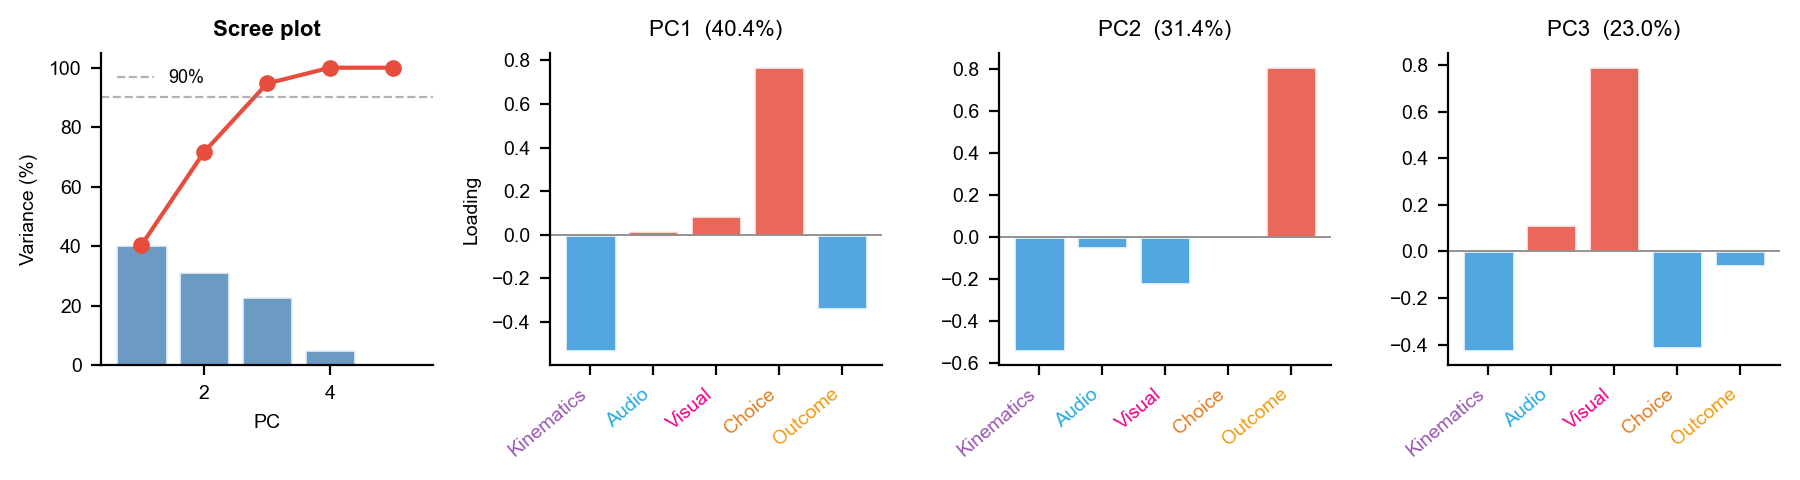

In [18]:
# ── 4b. Scree plot + PC loadings ─────────────────────────────────────────
if pca is None:
    print('Skipping — lesion data required.')
else:
    n_groups = X_norm.shape[1]   # 5
    n_load   = min(n_pcs_90, n_groups)

    fig, axes = plt.subplots(
        1, 1 + n_load,
        figsize=(2.5 + 2.2 * n_load, 2.5), dpi=200
    )

    # Scree
    ax = axes[0]
    ax.bar(range(1, n_groups + 1), pca.explained_variance_ratio_ * 100,
           color='steelblue', alpha=0.8, edgecolor='white')
    ax.plot(range(1, n_groups + 1), cumvar * 100, 'o-',
            color='#E74C3C', lw=1.5, markersize=5)
    ax.axhline(90, color='gray', ls='--', lw=0.8, alpha=0.6, label='90%')
    ax.set_xlabel('PC', fontsize=7)
    ax.set_ylabel('Variance (%)', fontsize=7)
    ax.set_title('Scree plot', fontsize=8, fontweight='bold')
    ax.legend(fontsize=6.5, frameon=False)
    sns.despine(ax=ax)

    # Loadings
    for i in range(n_load):
        ax = axes[i + 1]
        loadings    = pca.components_[i]
        bar_colors  = ['#E74C3C' if v > 0 else '#3498DB' for v in loadings]
        ax.bar(range(len(MERGE_ORDER)), loadings,
               color=bar_colors, edgecolor='white', alpha=0.85)
        ax.axhline(0, color='gray', lw=0.6)
        ax.set_xticks(range(len(MERGE_ORDER)))
        ax.set_xticklabels(MERGE_ORDER, rotation=40, ha='right', fontsize=7)
        for tick, grp in zip(ax.get_xticklabels(), MERGE_ORDER):
            tick.set_color(MERGE_COLORS[grp])
        ax.set_title(
            f'PC{i+1}  ({pca.explained_variance_ratio_[i]*100:.1f}%)',
            fontsize=8
        )
        if i == 0:
            ax.set_ylabel('Loading', fontsize=7)
        sns.despine(ax=ax)

    plt.tight_layout()
    plt.savefig('figures/Q1_pca_scree_loadings.svg', bbox_inches='tight', facecolor='white')
    plt.show()

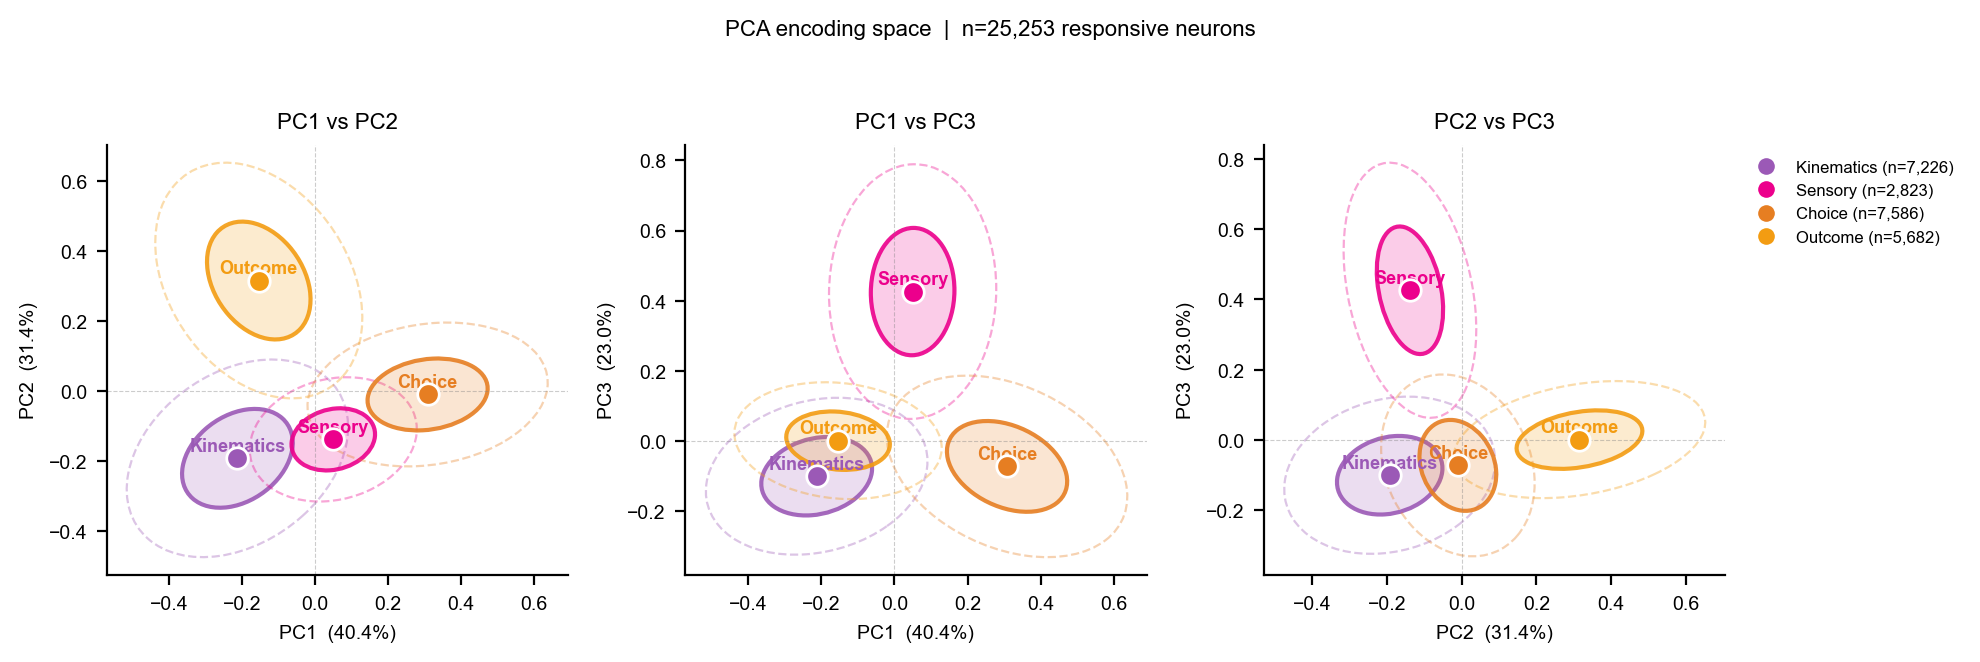

In [19]:
# ── 4c. 2D PCA scatter plots ──────────────────────────────────────────────
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms


def confidence_ellipse(x, y, ax, n_std=1.0, facecolor='none', **kwargs):
    if len(x) < 3: return
    cov     = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    rx, ry  = np.sqrt(1 + pearson), np.sqrt(1 - pearson)
    ellipse = Ellipse((0, 0), width=rx * 2, height=ry * 2,
                      facecolor=facecolor, **kwargs)
    t = (transforms.Affine2D()
         .rotate_deg(45)
         .scale(np.sqrt(cov[0, 0]) * n_std, np.sqrt(cov[1, 1]) * n_std)
         .translate(np.mean(x), np.mean(y)))
    ellipse.set_transform(t + ax.transData)
    ax.add_patch(ellipse)


if pca is None:
    print('Skipping — lesion data required.')
else:
    # Map each neuron's dominant_group to a coarse cloud label
    orig_to_cloud = {
        'position_only': 'kinematics', 'velocity': 'kinematics',
        'audio_context': 'sensory',    'audio_stim': 'sensory',
        'visual_context': 'sensory',   'visual_stim': 'sensory',
        'choice_spatial': 'choice',    'turn_onset': 'choice',
        'outcome': 'outcome',
        'mixed': 'mixed', 'unclassified': 'unclassified',
    }
    CLOUD_COLORS = {
        'kinematics': '#9B59B6', 'sensory': '#EC008C',
        'choice': '#E67E22',     'outcome': '#F39C12',
        'mixed': '#95A5A6',      'unclassified': '#BDC3C7',
    }
    CLOUD_LABELS = {
        'kinematics': 'Kinematics', 'sensory': 'Sensory',
        'choice': 'Choice',         'outcome': 'Outcome',
    }
    PLOT_CLOUDS = ['kinematics', 'sensory', 'choice', 'outcome']

    meta         = df_m1.loc[df_delta_resp.index]
    cloud_labels = meta['dominant_group'].map(orig_to_cloud).fillna('unclassified')

    pc_pairs = [(0, 1), (0, 2), (1, 2)]
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), dpi=200)

    for ax, (px, py) in zip(axes, pc_pairs):
        for cloud in PLOT_CLOUDS:
            mask = (cloud_labels == cloud).values
            if mask.sum() < 10: continue
            x, y  = scores[mask, px], scores[mask, py]
            color = CLOUD_COLORS[cloud]
            confidence_ellipse(x, y, ax, n_std=1.0,
                               facecolor=color, alpha=0.2, edgecolor='none')
            confidence_ellipse(x, y, ax, n_std=1.0,
                               facecolor='none', edgecolor=color, lw=1.5, alpha=0.9)
            confidence_ellipse(x, y, ax, n_std=2.0,
                               facecolor='none', edgecolor=color,
                               lw=0.8, alpha=0.35, ls='--')
            cx, cy = np.mean(x), np.mean(y)
            ax.scatter(cx, cy, color=color, s=60, zorder=5,
                       edgecolors='white', linewidths=1.0)
            ax.text(cx, cy + 0.01, CLOUD_LABELS[cloud],
                    ha='center', va='bottom', fontsize=6.5,
                    color=color, fontweight='bold')

        ax.axhline(0, color='gray', lw=0.4, ls='--', alpha=0.4)
        ax.axvline(0, color='gray', lw=0.4, ls='--', alpha=0.4)
        vx = pca.explained_variance_ratio_[px] * 100
        vy = pca.explained_variance_ratio_[py] * 100
        ax.set_xlabel(f'PC{px+1}  ({vx:.1f}%)', fontsize=7)
        ax.set_ylabel(f'PC{py+1}  ({vy:.1f}%)', fontsize=7)
        ax.set_title(f'PC{px+1} vs PC{py+1}', fontsize=8)
        sns.despine(ax=ax)

    handles = [
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor=CLOUD_COLORS[c], markersize=7,
                   label=f'{CLOUD_LABELS[c]} (n={(cloud_labels==c).sum():,})')
        for c in PLOT_CLOUDS
    ]
    axes[-1].legend(handles=handles, fontsize=6, frameon=False,
                    bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.suptitle(
        f'PCA encoding space  |  n={len(scores):,} responsive neurons',
        fontsize=8, y=1.02
    )
    plt.tight_layout()
    plt.savefig('figures/Q1_pca_2d_scatter.svg', bbox_inches='tight', facecolor='white')
    plt.show()

In [ ]:
# ── 4d. 3D PCA scatter with 1-SD ellipsoids ──────────────────────────────
from mpl_toolkits.mplot3d import Axes3D

if pca is None:
    print('Skipping — lesion data required.')
else:
    fig = plt.figure(figsize=(6.5, 5.5), dpi=200)
    ax  = fig.add_subplot(111, projection='3d')

    for cloud in PLOT_CLOUDS:
        mask = (cloud_labels == cloud).values
        if mask.sum() < 10: continue
        x, y, z = scores[mask, 0], scores[mask, 1], scores[mask, 2]
        color    = CLOUD_COLORS[cloud]
        n        = mask.sum()

        # Subsampled scatter
        rng     = np.random.default_rng(seed=42)
        sub_idx = rng.choice(n, size=min(600, n), replace=False)
        ax.scatter(x[sub_idx], y[sub_idx], z[sub_idx],
                   color=color, alpha=0.1, s=3, linewidths=0)

        # 1-SD ellipsoid
        cx, cy, cz = np.mean(x), np.mean(y), np.mean(z)
        rx, ry, rz = np.std(x),  np.std(y),  np.std(z)
        u  = np.linspace(0, 2 * np.pi, 25)
        v  = np.linspace(0, np.pi, 25)
        xs = cx + rx * np.outer(np.cos(u), np.sin(v))
        ys = cy + ry * np.outer(np.sin(u), np.sin(v))
        zs = cz + rz * np.outer(np.ones_like(u), np.cos(v))
        ax.plot_surface(xs, ys, zs, color=color, alpha=0.15, linewidth=0)
        ax.scatter(cx, cy, cz, color=color, s=100, zorder=10,
                   edgecolors='white', linewidths=1.2)
        ax.text(cx, cy, cz + 0.05, f'{CLOUD_LABELS[cloud]}\n(n={n:,})',
                ha='center', va='bottom', fontsize=6.5,
                color=color, fontweight='bold')

    v1, v2, v3 = [pca.explained_variance_ratio_[i] * 100 for i in range(3)]
    ax.set_xlabel(f'PC1 ({v1:.1f}%)', fontsize=7, labelpad=5)
    ax.set_ylabel(f'PC2 ({v2:.1f}%)', fontsize=7, labelpad=5)
    ax.set_zlabel(f'PC3 ({v3:.1f}%)', fontsize=7, labelpad=5)
    ax.set_title(
        f'PCA encoding space — PC1/2/3\nn={len(scores):,} neurons',
        fontsize=8
    )

    for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
        pane.fill = False
        pane.set_edgecolor('none')
    for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
        axis._axinfo['grid']['color'] = (1, 1, 1, 0)
    ax.grid(False)
    ax.view_init(elev=25, azim=-40)

    handles = [
        plt.Line2D([0], [0], marker='o', color='w',
                   markerfacecolor=CLOUD_COLORS[c], markersize=7,
                   label=f'{CLOUD_LABELS[c]} (n={(cloud_labels==c).sum():,})')
        for c in PLOT_CLOUDS
    ]
    ax.legend(handles=handles, fontsize=6, frameon=False,
              loc='upper left', bbox_to_anchor=(-0.05, 1.0))

    plt.tight_layout()
    plt.savefig('figures/Q1_pca_3d.svg', bbox_inches='tight', facecolor='white')
    plt.show()

## Section 5 — Coupling Model: Population Dynamics

The coupling model adds the top-5 population PCs (convolved with temporal lag bases) as additional predictors on top of Model 1's 9 behavioral groups. This captures variance driven by correlated network activity beyond individual behavioral variables.

**Key questions:**
- **5a** Does coupling improve FDE? By how much, and for which neurons?
- **5b** Does coupling gain differ by functional type (kinematic vs choice vs sensory)?
- **5c** What behavioral signal do the network PCs represent?
- **5d** Does coupling *substitute* (absorb) behavioral coding, or *add* to it?
- **5e** Variance decomposition: total ΔFDE per type including network contribution
- **5f** Do neurons change their dominant classification when coupling is added?

Neurons in both models  : 56,141
Coupling gain — all     : median=+0.0259
Coupling gain — resp.   : median=+0.0477
% positive gain (resp.) : 92.2%


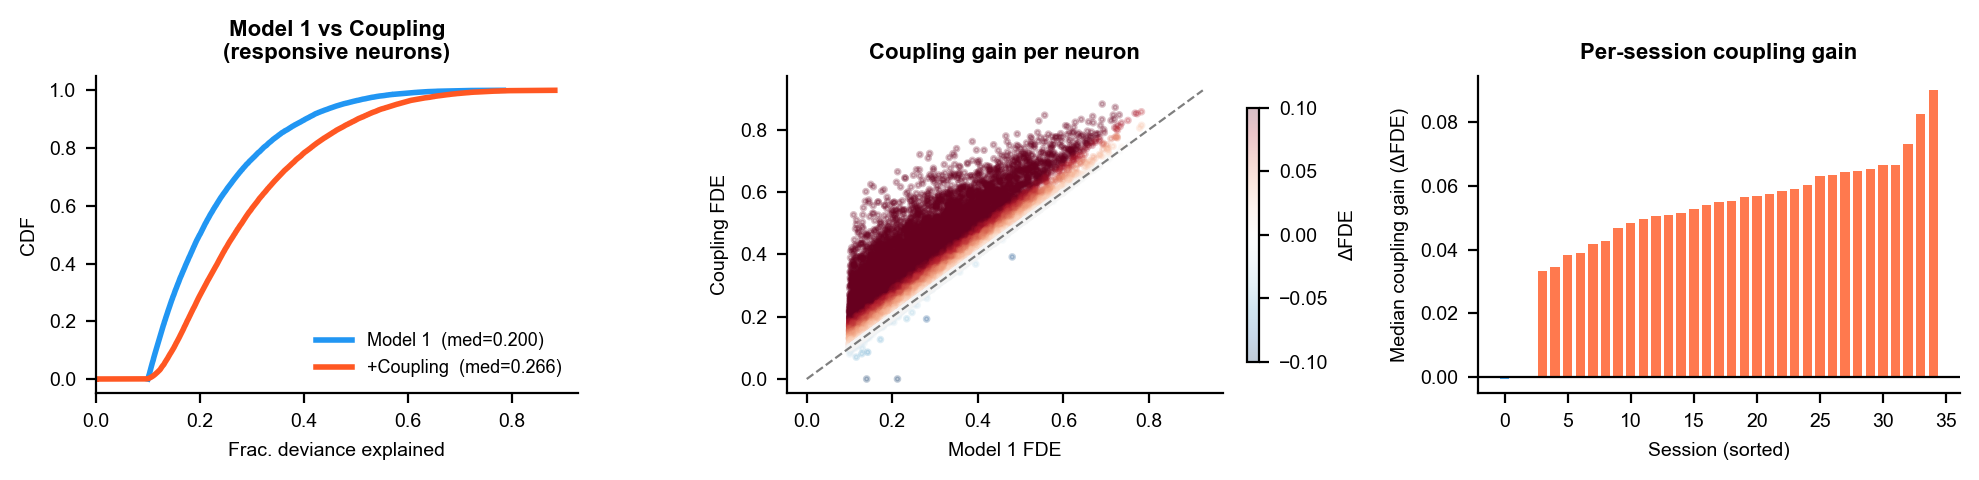

In [25]:
# ── 5a. Coupling FDE gain overview ──────────────────────────────────────
# Align neurons present in both models (same session + neuron index)
common_idx     = df_m1.index.intersection(df_coup.index)
fde_m1_c       = df_m1.loc[common_idx, 'test_frac_dev'].values
fde_coup_c     = df_coup.loc[common_idx, 'test_frac_dev'].values
coup_gain      = fde_coup_c - fde_m1_c
resp_both      = df_m1.loc[common_idx, 'is_responsive'].values

print(f'Neurons in both models  : {len(common_idx):,}')
print(f'Coupling gain — all     : median={np.nanmedian(coup_gain):+.4f}')
print(f'Coupling gain — resp.   : median={np.nanmedian(coup_gain[resp_both]):+.4f}')
print(f'% positive gain (resp.) : {(coup_gain[resp_both] > 0).mean()*100:.1f}%')

fig, axes = plt.subplots(1, 3, figsize=(10, 2.5), dpi=200)

# CDF: Model 1 vs Coupling
ax = axes[0]
for fde, lbl, col in [
    (fde_m1_c[resp_both],   'Model 1',   '#2196F3'),
    (fde_coup_c[resp_both], '+Coupling',  '#FF5722'),
]:
    x = np.sort(fde); y = np.linspace(0, 1, len(x))
    ax.plot(x, y, color=col, lw=2, label=f'{lbl}  (med={np.median(x):.3f})')
ax.set_xlabel('Frac. deviance explained', fontsize=7)
ax.set_ylabel('CDF', fontsize=7)
ax.set_title('Model 1 vs Coupling\n(responsive neurons)', fontsize=8, fontweight='bold')
ax.legend(fontsize=6.5, frameon=False)
ax.set_xlim(0, None)
sns.despine(ax=ax)

# Scatter: M1 FDE vs Coupling FDE
ax = axes[1]
gain_clipped = np.clip(coup_gain[resp_both], -0.15, 0.15)
sc = ax.scatter(fde_m1_c[resp_both], fde_coup_c[resp_both],
                s=3, alpha=0.25, c=gain_clipped, cmap='RdBu_r', vmin=-0.1, vmax=0.1)
lim = max(fde_m1_c[resp_both].max(), fde_coup_c[resp_both].max()) * 1.05
ax.plot([0, lim], [0, lim], 'k--', lw=0.8, alpha=0.5)
ax.set_xlabel('Model 1 FDE', fontsize=7)
ax.set_ylabel('Coupling FDE', fontsize=7)
ax.set_title('Coupling gain per neuron', fontsize=8, fontweight='bold')
plt.colorbar(sc, ax=ax, label='ΔFDE', shrink=0.8, fraction=0.046)
sns.despine(ax=ax)

# Per-session median gain
ax = axes[2]
df_both = df_m1.loc[common_idx, ['mouse_ID', 'date', 'is_responsive']].copy()
df_both['coup_gain'] = coup_gain
sess_gains = (
    df_both[df_both['is_responsive']]
    .groupby(['mouse_ID', 'date'])['coup_gain']
    .median().reset_index(name='median_gain')
)
ax.bar(range(len(sess_gains)), sess_gains['median_gain'].sort_values().values,
       color=[
           '#FF5722' if v > 0 else '#2196F3'
           for v in sess_gains['median_gain'].sort_values().values
       ], alpha=0.8, width=0.75)
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('Session (sorted)', fontsize=7)
ax.set_ylabel('Median coupling gain (ΔFDE)', fontsize=7)
ax.set_title('Per-session coupling gain', fontsize=8, fontweight='bold')
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig('figures/Q1_coupling_gain_overview.svg', bbox_inches='tight', facecolor='white')
plt.show()

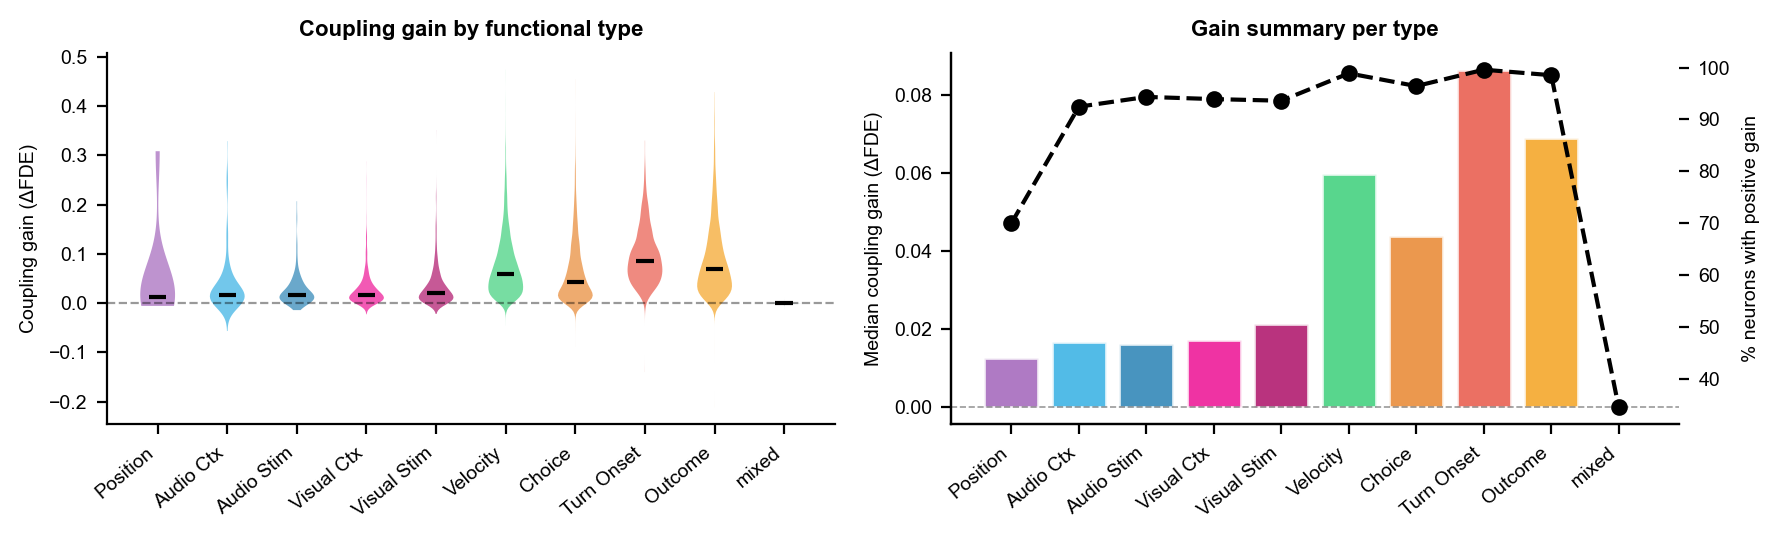

In [26]:
# ── 5b. Coupling gain by functional type ─────────────────────────────────
df_both = df_m1.loc[common_idx].copy()
df_both['coup_gain'] = coup_gain

if 'neuron_class' not in df_both.columns:
    print('Skipping — lesion data required for neuron_class.')
else:
    MIN_N = 5
    cls_candidates = [
        g for g in M1_GROUPS if g in df_both['dominant_group'].values
    ] + ['mixed']
    data_by_type, cls_present = [], []
    for c in cls_candidates:
        d = df_both[
            (df_both['neuron_class'] == c) & df_both['is_responsive']
        ]['coup_gain'].dropna().values
        if len(d) >= MIN_N:
            data_by_type.append(d)
            cls_present.append(c)

    fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), dpi=200)

    # Violin: gain distribution per type
    ax = axes[0]
    vp = ax.violinplot(data_by_type, positions=range(len(cls_present)),
                       showmedians=True, showextrema=False)
    for pc, c in zip(vp['bodies'], cls_present):
        pc.set_facecolor(CLASS_COLORS.get(c, 'gray'))
        pc.set_alpha(0.65)
    vp['cmedians'].set_color('black')
    vp['cmedians'].set_linewidth(1.5)
    ax.axhline(0, color='k', lw=0.8, ls='--', alpha=0.4)
    ax.set_xticks(range(len(cls_present)))
    ax.set_xticklabels([GROUP_LABELS.get(c, c) for c in cls_present],
                       rotation=40, ha='right', fontsize=7)
    ax.set_ylabel('Coupling gain (ΔFDE)', fontsize=7)
    ax.set_title('Coupling gain by functional type', fontsize=8, fontweight='bold')
    sns.despine(ax=ax)

    # Bar: median gain + % positive per type
    ax = axes[1]
    summary = []
    for c in cls_present:
        sub = df_both[
            (df_both['neuron_class'] == c) & df_both['is_responsive']
        ]['coup_gain'].dropna()
        summary.append((c, np.nanmedian(sub), (sub > 0).mean() * 100, len(sub)))
    summary_df = pd.DataFrame(summary,
                               columns=['class', 'median_gain', 'pct_positive', 'n'])

    x   = np.arange(len(summary_df))
    ax2 = ax.twinx()
    ax.bar(x, summary_df['median_gain'],
           color=[CLASS_COLORS.get(c, 'gray') for c in cls_present],
           alpha=0.8, edgecolor='white')
    ax2.plot(x, summary_df['pct_positive'], 'ko--', ms=5, lw=1.5)
    ax.axhline(0, color='k', lw=0.6, ls='--', alpha=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels([GROUP_LABELS.get(c, c) for c in cls_present],
                       rotation=40, ha='right', fontsize=7)
    ax.set_ylabel('Median coupling gain (ΔFDE)', fontsize=7)
    ax2.set_ylabel('% neurons with positive gain', fontsize=7)
    ax.set_title('Gain summary per type', fontsize=8, fontweight='bold')
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.savefig('figures/Q1_coupling_gain_by_type.svg', bbox_inches='tight', facecolor='white')
    plt.show()

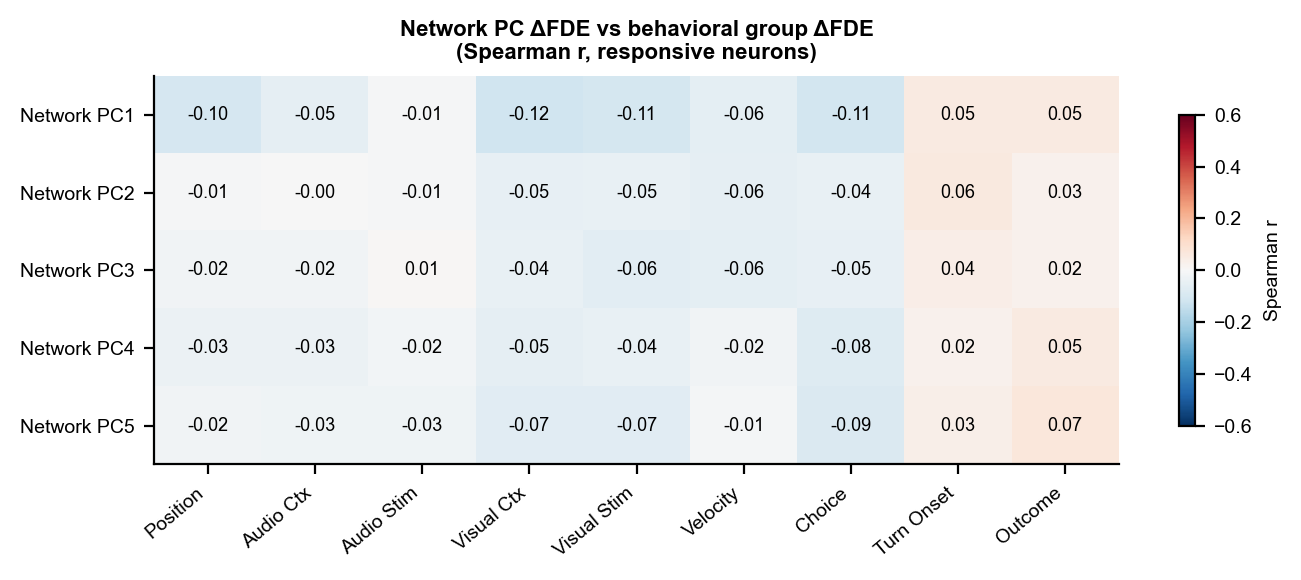

High |r| → that network PC co-varies with the corresponding behavioral variable


In [27]:
# ── 5c. What behavioral signal do the network PCs represent? ─────────────
# Spearman r between each network PC's ΔFDE and each behavioral group's ΔFDE
pc_cols  = [f'delta_fd_network_pc{i+1}' for i in range(5)
            if f'delta_fd_network_pc{i+1}' in df_coup.columns]
beh_cols = [f'delta_fd_{g}' for g in M1_GROUPS
            if f'delta_fd_{g}' in df_coup.columns]

if not pc_cols or not beh_cols:
    print('Skipping — coupling lesion results required.')
else:
    df_cr    = df_coup[resp_coup].copy()
    corr_mat = np.zeros((len(pc_cols), len(beh_cols)))
    for i, pc_col in enumerate(pc_cols):
        for j, beh_col in enumerate(beh_cols):
            mask = np.isfinite(df_cr[pc_col]) & np.isfinite(df_cr[beh_col])
            if mask.sum() > 10:
                r, _ = stats.spearmanr(
                    df_cr.loc[mask, pc_col], df_cr.loc[mask, beh_col]
                )
                corr_mat[i, j] = r

    fig, ax = plt.subplots(figsize=(7, 3.0), dpi=200)
    im = ax.imshow(corr_mat, cmap='RdBu_r', vmin=-0.6, vmax=0.6, aspect='auto')
    ax.set_xticks(range(len(beh_cols)))
    ax.set_xticklabels(
        [GROUP_LABELS.get(c.replace('delta_fd_', ''), c) for c in beh_cols],
        rotation=40, ha='right', fontsize=7
    )
    ax.set_yticks(range(len(pc_cols)))
    ax.set_yticklabels([f'Network PC{i+1}' for i in range(len(pc_cols))], fontsize=7)
    ax.set_title('Network PC ΔFDE vs behavioral group ΔFDE\n(Spearman r, responsive neurons)',
                 fontsize=8, fontweight='bold')
    plt.colorbar(im, ax=ax, label='Spearman r', shrink=0.8)
    for i in range(corr_mat.shape[0]):
        for j in range(corr_mat.shape[1]):
            ax.text(j, i, f'{corr_mat[i,j]:.2f}', ha='center', va='center',
                    fontsize=6.5,
                    color='white' if abs(corr_mat[i, j]) > 0.3 else 'black')
    plt.tight_layout()
    plt.savefig('figures/Q1_network_pc_correlation.svg', bbox_inches='tight', facecolor='white')
    plt.show()
    print('High |r| → that network PC co-varies with the corresponding behavioral variable')

         group  median_shift  pct_decrease
 position_only     -0.000306     67.719015
 audio_context     -0.000208     59.008334
    audio_stim     -0.000149     58.140339
visual_context     -0.000278     60.302646
   visual_stim     -0.000315     62.073204
      velocity     -0.007469     84.099551
choice_spatial     -0.005649     83.561854
    turn_onset     -0.001124     74.263548
       outcome     -0.006519     85.121174


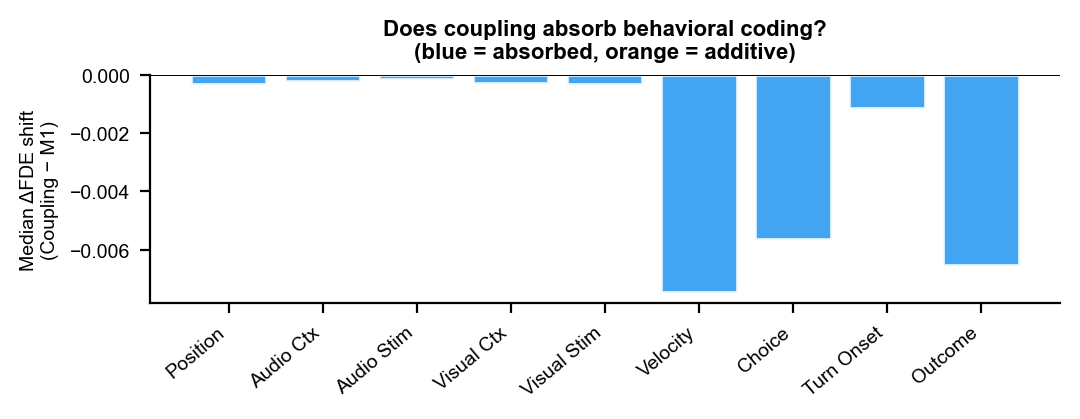

In [28]:
# ── 5d. Does coupling substitute or add to behavioral coding? ────────────
# For each behavioral group: compare delta_FDE in M1 vs coupling model.
# If coupling shifts ΔFDE down → network absorbed that signal.
# If no change → coupling adds orthogonal variance.
beh_both = [g for g in M1_GROUPS
            if f'delta_fd_{g}' in df_m1.columns
            and f'delta_fd_{g}' in df_coup.columns]

if not beh_both:
    print('Skipping — lesion results required for both models.')
else:
    shared = df_m1.index.intersection(df_coup.index)
    resp   = df_m1.loc[shared, 'is_responsive'].values

    substitution = []
    for g in beh_both:
        col   = f'delta_fd_{g}'
        x_m1  = df_m1.loc[shared, col].values[resp]
        x_co  = df_coup.loc[shared, col].values[resp]
        delta = x_co - x_m1    # positive = coupling adds; negative = coupling absorbs
        substitution.append({
            'group': g,
            'median_shift': np.nanmedian(delta),
            'pct_decrease': (delta < 0).mean() * 100,
        })

    sub_df = pd.DataFrame(substitution)
    print(sub_df.to_string(index=False))

    fig, ax = plt.subplots(figsize=(5.5, 2.2), dpi=200)
    bar_colors = [
        '#FF5722' if v > 0 else '#2196F3'
        for v in sub_df['median_shift']
    ]
    ax.bar(range(len(sub_df)), sub_df['median_shift'],
           color=bar_colors, alpha=0.85, edgecolor='white')
    ax.axhline(0, color='k', lw=0.7)
    ax.set_xticks(range(len(sub_df)))
    ax.set_xticklabels(
        [GROUP_LABELS.get(g, g) for g in sub_df['group']],
        rotation=40, ha='right', fontsize=7
    )
    ax.set_ylabel('Median ΔFDE shift\n(Coupling − M1)', fontsize=7)
    ax.set_title('Does coupling absorb behavioral coding?\n'
                 '(blue = absorbed, orange = additive)', fontsize=8, fontweight='bold')
    sns.despine()
    plt.tight_layout()
    plt.savefig('figures/Q1_coupling_substitution.svg', bbox_inches='tight', facecolor='white')
    plt.show()

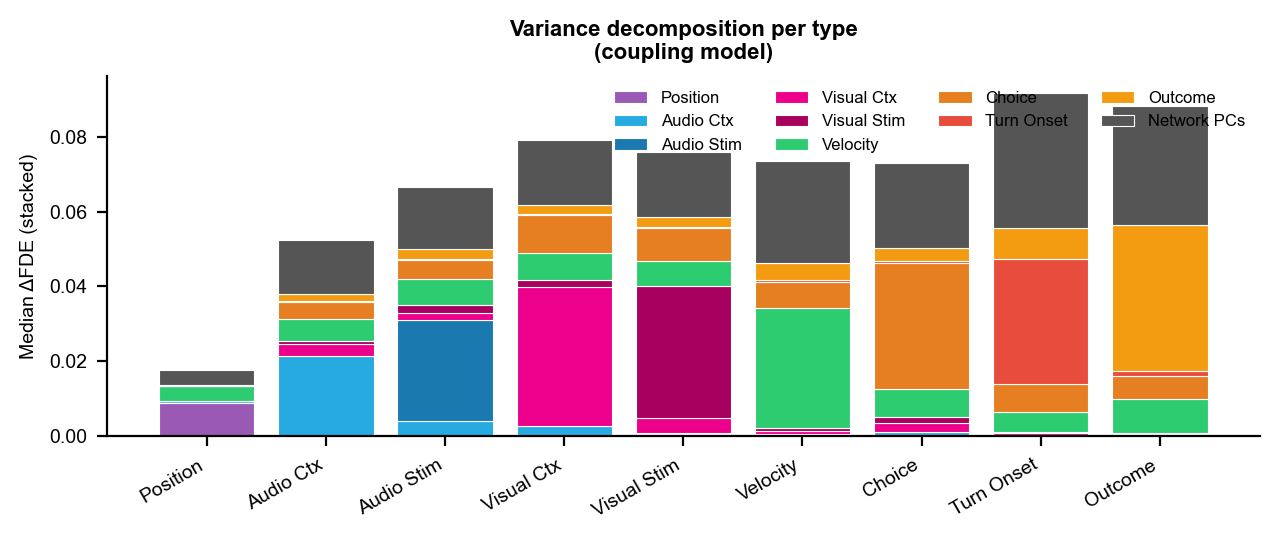

In [29]:
# ── 5e. Variance decomposition per type incl. network contribution ────────
all_coup_groups = [
    g for g in M1_GROUPS + [f'network_pc{i+1}' for i in range(5)]
    if f'delta_fd_{g}' in df_coup.columns
]
if 'neuron_class' not in df_coup.columns or not all_coup_groups:
    print('Skipping — coupling lesion results required.')
else:
    df_cr        = df_coup[resp_coup].copy()
    types_to_plot = [g for g in M1_GROUPS if g in df_cr['dominant_group'].values]
    pc_all_cols   = [f'delta_fd_network_pc{i+1}' for i in range(5)
                     if f'delta_fd_network_pc{i+1}' in df_cr.columns]

    fig, ax = plt.subplots(figsize=(6.5, 2.8), dpi=200)
    x      = np.arange(len(types_to_plot))
    bottom = np.zeros(len(types_to_plot))

    for g in M1_GROUPS:
        col = f'delta_fd_{g}'
        if col not in df_cr.columns: continue
        heights = [
            df_cr[df_cr['dominant_group'] == t][col].clip(lower=0).median()
            for t in types_to_plot
        ]
        ax.bar(x, heights, bottom=bottom, color=GROUP_COLORS.get(g, 'gray'),
               label=GROUP_LABELS.get(g, g), edgecolor='white', linewidth=0.4)
        bottom += np.array(heights)

    if pc_all_cols:
        net_heights = [
            df_cr[df_cr['dominant_group'] == t][pc_all_cols]
            .clip(lower=0).sum(axis=1).median()
            for t in types_to_plot
        ]
        ax.bar(x, net_heights, bottom=bottom, color='#555555',
               label='Network PCs', edgecolor='white', linewidth=0.4)

    ax.set_xticks(x)
    ax.set_xticklabels([GROUP_LABELS.get(g, g) for g in types_to_plot],
                       rotation=30, ha='right', fontsize=7)
    ax.set_ylabel('Median ΔFDE (stacked)', fontsize=7)
    ax.set_title('Variance decomposition per type\n(coupling model)',
                 fontsize=8, fontweight='bold')
    ax.legend(fontsize=6, frameon=False, ncol=4, loc='upper right')
    sns.despine()
    plt.tight_layout()
    plt.savefig('figures/Q1_coupling_variance_decomp.svg', bbox_inches='tight', facecolor='white')
    plt.show()

Overall: 75.3% of responsive neurons change class


AttributeError: 'int' object has no attribute 'sort_values'

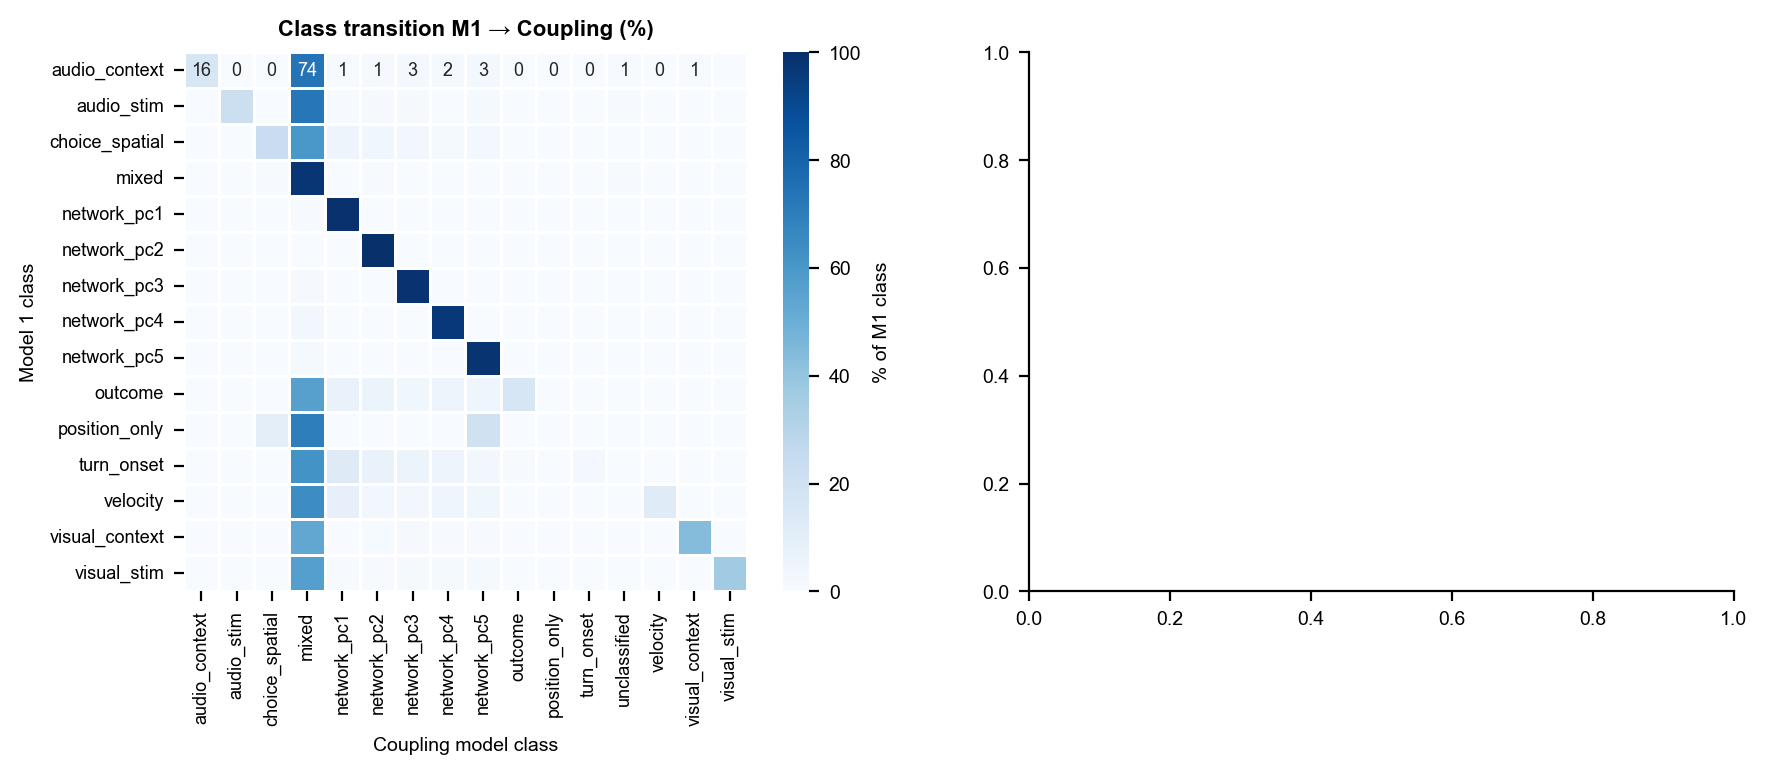

In [30]:
# ── 5f. Do neurons change class when coupling is added? ──────────────────
shared = df_m1.index.intersection(df_coup.index)
if 'neuron_class' not in df_m1.columns or 'neuron_class' not in df_coup.columns:
    print('Skipping — lesion data required for both models.')
else:
    df_reclass = pd.DataFrame({
        'm1_class':   df_m1.loc[shared, 'neuron_class'],
        'coup_class': df_coup.loc[shared, 'neuron_class'],
        'is_resp':    df_m1.loc[shared, 'is_responsive'],
    })[df_m1.loc[shared, 'is_responsive']]

    pct_changed = (
        (df_reclass['m1_class'] != df_reclass['coup_class']).mean() * 100
    )
    print(f'Overall: {pct_changed:.1f}% of responsive neurons change class')

    # Transition matrix
    trans = pd.crosstab(
        df_reclass['m1_class'], df_reclass['coup_class'],
        normalize='index'
    ) * 100

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), dpi=200)

    ax = axes[0]
    sns.heatmap(trans.fillna(0), cmap='Blues', annot=True, fmt='.0f', ax=ax,
                cbar_kws={'label': '% of M1 class'},
                linewidths=0.4, annot_kws={'size': 6.5})
    ax.set_xlabel('Coupling model class', fontsize=7)
    ax.set_ylabel('Model 1 class', fontsize=7)
    ax.set_title('Class transition M1 → Coupling (%)', fontsize=8, fontweight='bold')
    ax.tick_params(labelsize=6.5)

    # Bar: % changed class per M1 type
    ax = axes[1]
    changed_per_type = (
        (df_reclass['m1_class'] != df_reclass['coup_class'])
        .groupby(df_reclass['m1_class']).mean() * 100
        .sort_values(ascending=False)
    )
    ax.bar(
        range(len(changed_per_type)), changed_per_type.values,
        color=[CLASS_COLORS.get(c, 'gray') for c in changed_per_type.index],
        edgecolor='white', alpha=0.9
    )
    ax.set_xticks(range(len(changed_per_type)))
    ax.set_xticklabels(
        [GROUP_LABELS.get(c, c) for c in changed_per_type.index],
        rotation=40, ha='right', fontsize=7
    )
    ax.set_ylabel('% neurons that changed class', fontsize=7)
    ax.set_title('Classification stability\nwhen coupling is added',
                 fontsize=8, fontweight='bold')
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.savefig('figures/Q1_coupling_reclassification.svg', bbox_inches='tight', facecolor='white')
    plt.show()